# Modelos de ensamble
## Proyecto Integrador — Avance 5

**Equipo 1**

| Nombre | Matrícula |
|---|---|
| Isaura Yutsil Flores Escamilla | A01796552 |
| Paola Alejandra León Guarneros | A01796230 |
| Dylan Ulises Quiroz Hernández  | A01796578 |

**Fecha:** 1 de noviembre del 2026

## Resumen

En este avance se construyen **modelos de ensamble** sobre el preentrenamiento autosupervisado CPC para reconocer las siete actividades de manejo manual de cargas (`N`, `LF`, `K`, `PT`, `LT`, `W`, `PF`). La entrada es la captura de movimiento (MVNX): 30 variables a 12 Hz, en ventanas de 4 s. Se prueban:

- Un **ensamble homogéneo**: cinco CPC-GRU iguales, entrenados con distinta semilla;

- Cinco **ensambles heterogéneos** con los CPC de GRU, LSTM y sLSTM: 

    - **Concatenación de representaciones:** Cada CPC convierte la ventana en su vector `c_t` de 256 números. Los tres vectores (uno para GRU, uno para LSTM y uno para sLSTM) se pegan para tener uno solo de 768 entradas, y ese vector final sirve como entrada para la regresión logística, es decir, la información de CPC se junta antes de clasificar.

    - **Votación suave:** Cada CPC tiene su propia regresión logística (o sonda), y casa regresión da una probabilidad de pertenecer a una de las 7 actividades. Se promedian las tres probabilidades y gana la actividad con el promedio más alto. Se juntan *después* del proceso de clasificación. 

    - **Stacking:** Parte de las mismas tres regresiones, pero en lugar de promediar, se usa un meta-modelo (otra regresión logística) para que aprenda el peso que se debe de dar a cada regresión. Para entrenarlo sin hacer trampa se usan predicciones fuera de muestra: las sondas se entrenan con unos sujetos de entrenamiento y predicen otros que no vieron. Así el meta-modelo aprende con predicciones "honestas" y muchos datos.

    - **Blending:** Es la misma idea que el stacking, pero el meta-modelo se entrena con las predicciones sobre un solo sujeto apartado, el de validación interna. Es más simple, pero tiene pocos datos. Por eso se sobreajustó: tuvo el mejor F1 en validación (0.880) y uno de los peores en el sujeto evaluado (0.813).

    - **Un CPC con los tres autorregresivos entrenados juntos:** Es un solo modelo con un encoder compartido y, encima, las tres redes de contexto (GRU, LSTM y sLSTM), cada una con su propio predictor. Se preentrenan juntas, promediando su pérdida InfoNCE. Al final se pegan sus tres c_T y una regresión logística clasifica. A diferencia de las cuatro anteriores, que combinan CPC entrenados por separado, aquí el ensamble está dentro del modelo.

En todos, el clasificador final es **lineal**. Los hiperparámetros se optimizan en cada ronda con un sujeto de validación interna. Todo se evalúa dejando un sujeto fuera (LOSO) con los sujetos 1–12, en la misma tabla que los modelos individuales del avance 4.

El **ensamble de semillas CPC-GRU** es el mejor de los modelos CPC con clasificador lineal, con F1 macro de **0.873 ± 0.021**:

- supera por 0.060 a la mejor sonda individual y mejora en los 12 sujetos;
- sin ajuste fino, queda a 0.005 de la GRU con ajuste fino y a 0.021 del Random Forest;
- su peor sujeto (0.827) es comparable al del Random Forest (0.823).

Con **pocas etiquetas** supera al Random Forest en todos los tamaños probados; por ejemplo, 0.691 contra 0.620 con 10 ventanas por actividad. Por eso se elige como **modelo final**: etiquetar es la parte más cara de llevar el sistema a una planta.

### **Baseline considerado**

Se consideran el GRU y sLSTM con CPC, que fueron las dos mejores redes del avance 4 (F1 macro 0.878 y 0.871 con ajuste fino), como el baseline para esta fase. La LSTM se agrega como tercer modelo de contexto. Sus preentrenamientos CPC ya existen en el notebook 10 y se reutilizan sin reentrenar.

### **Optimización de hiperparámetros.** 

Se ajustan la regularización `C` de cada clasificador lineal, el número de semillas y la forma de combinarlas, y la regularización del meta-modelo. Todo se elige en cada ronda con el sujeto de validación interna, nunca con el sujeto evaluado.

### **Criterios para el modelo final**

Los criterios utilizados para la eveluación del modelo fueron, en orden: (1) F1 macro en personas nuevas; (2) estabilidad entre personas (peor sujeto); (3) desempeño con **pocas etiquetas**, porque anotar actividades es la parte más cara de llevar el sistema a una planta; (4) costo de entrenamiento y que pueda usarse en tiempo real (modelo causal).

# 1. Configuración

In [1]:
import copy, json, math, os, re, time
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from joblib import Parallel, delayed
from numpy.lib.stride_tricks import sliding_window_view
from scipy.interpolate import interp1d
from scipy.signal import butter, sosfiltfilt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Datos y validación (iguales a los avances anteriores) -----------------------------
SEED = 0
TARGET_FS = 12                         # Hz
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada LOSO
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
WIN, SUP_HOP, CPC_HOP = 48, 6, 24      # ventana de 4 s; una ventana etiquetada cada 0.5 s y una sin etiqueta (CPC) cada 2 s
SCALER_FIT_POINTS = 250_000            # instantes que se muestrean para ajustar el escalador
PROBE_TRAIN_MAX = 15_000               # ventanas de entrenamiento de las sondas lineales (las mismas que el notebook 10)

# ----------------------------- Preentrenamiento CPC (los mismos valores del notebook 10) -----------------------------
CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 20, 2, 3   # épocas máximas; cada cuántas se evalúa la sonda; paciencia
CPC_BATCH, CPC_LR, GRAD_CLIP, N_ANCHORS = 128, 5e-4, 1.0, 4
HORIZONS = tuple(range(1, 13))         # CPC predice de 1 a 12 pasos adelante (hasta 1 s)
STEPS_CAP = None                       # límite de pasos por época (sólo para la corrida de prueba)

# ----------------------------- Ensambles e hiperparámetros -----------------------------
ENSEMBLE_SEEDS = (0, 1, 2, 3, 4)       # semillas del ensamble homogéneo (la 0 es el CPC-GRU del notebook 10)
SEED_K_GRID = (2, 3, 4, 5)             # cuántas semillas combinar: se elige en cada ronda
C_GRID = (0.003, 0.01, 0.03, 0.1, 0.3, 1.0)   # regularización de las sondas lineales (menor C = más regularización)
META_C_GRID = (0.01, 0.1, 1.0, 10.0)   # regularización del meta-modelo de stacking y blending
STACK_FOLDS = 5                        # pliegues por sujeto para las predicciones fuera de muestra del stacking
LABEL_SIZES = (1, 5, 10, 25, 50, 100)  # ventanas etiquetadas por actividad en el experimento de pocas etiquetas
LABEL_REPS = 3                         # repeticiones de cada tamaño con distintas muestras
RF_PARAMS = dict(n_estimators=300, max_features="sqrt", min_samples_leaf=2, class_weight="balanced_subsample",
                 n_jobs=-1, random_state=SEED)          # Random Forest del avance 4 (el ajuste no lo mejoró)

# Corrida de prueba rápida (2 rondas, pocas épocas) para revisar que todo funciona: AVANCE5_QUICK=1
QUICK = os.environ.get("AVANCE5_QUICK") == "1"
FOLDS = CV_SUBJECTS                    # sujetos que se evalúan (rondas LOSO)
if QUICK:
    FOLDS, CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE, STEPS_CAP = (1, 2), 2, 1, 1, 5
    C_GRID, META_C_GRID, LABEL_SIZES, LABEL_REPS = (0.1, 1.0), (0.1, 1.0), (1, 10), 1
N_JOBS = min(len(C_GRID), os.cpu_count() or 1)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"                     # exportación MVNX sincronizada
RECOVER_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}_mvnx_recuperados"  # caché de los ensayos recuperados
MVNX_DIR, MVNX_LABEL_DIR = REPO_DIR / "datos_unzipped" / "mvnx_files", REPO_DIR / "datos_unzipped" / "Labels 2"
SAVED_DIR = REPO_DIR / "checkpoints" / f"cpc10_loso_mvnx_metodos_fs{TARGET_FS}"   # rondas del notebook 10 (CPC y ajuste fino)
RUN_DIR = REPO_DIR / "checkpoints" / (f"avance5_fs{TARGET_FS}" + ("_quick" if QUICK else ""))   # todo lo nuevo de este avance
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = RUN_DIR / "progreso.log"
assert (SYNC_DIR / "metadata.json").exists(), f"Falta la exportación sincronizada en {SYNC_DIR.relative_to(REPO_DIR)}"
assert SAVED_DIR.exists(), f"Faltan las rondas del notebook 10 en {SAVED_DIR.relative_to(REPO_DIR)}"

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]
LABEL_NAMES = {"N": "Postura neutral", "LF": "Levantar desde el piso", "K": "Mantener levantado", "PT": "Colocar en la mesa",
               "LT": "Levantar desde la mesa", "W": "Caminar / cargar", "PF": "Colocar en el piso"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


def log(message):
    """Imprime un mensaje con hora y lo guarda en progreso.log (útil para seguir corridas largas)."""
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | rondas: {len(FOLDS)} | QUICK: {QUICK}")
print(f"Resultados nuevos en: {RUN_DIR.relative_to(REPO_DIR)}")

PyTorch 2.11.0 | dispositivo: mps | rondas: 12 | QUICK: False
Resultados nuevos en: checkpoints/avance5_fs12


# 2. Datos

Se decidió partir de los datos que utilizamos en el **avance 4**, que es solo con la base de datos que contiene la captura de movimiento (MVNX) a 12 Hz, utilizando las etiquetas del archivo `label_mvnx`. 

De las 782 columnas originales del dataset, se preservan 30, de acuerdo al análisis de características desarrollado en entregas anteriores. Las variables incluidas describen postura, altura, alcance, velocidades y apoto de los pies, con lados fijos (`izq_*`, `der_*`). La sEMG se descarta por el bajo desempeño observado en intentos anteriores. 


*Nota: Dado que los 3 ensayos del sujeto 7 los habíamos excluido por su comportamiento atípico en sEMG, se incorporan en este ejercicio.*

In [2]:
# Columnas MVNX crudas que se necesitan para calcular las 30 variables
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]          # posiciones (m)
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]               # velocidades (m/s)
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]                            # giros (rad/s)
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]               # flexiones (°)
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]   # hombros en XZY
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]            # contactos (0/1)
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}   # nombre de columna -> posición
SIDES = (("izq", "Left"), ("der", "Right"))           # prefijo en español y nombre del lado en el MVNX


def derive(raw):
    """Columnas MVNX crudas -> las 30 variables, con los lados fijos (izquierdo / derecho)."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    # --- Postura (14): ángulos articulares en grados ---
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for lado, s in SIDES:
        out[f"{lado}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{lado}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{lado}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{lado}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{lado}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{lado}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    # --- Alturas y alcance (6): en metros; el alcance es la distancia horizontal mano–pelvis ---
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{lado}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                               col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    # --- Velocidades (6): normas, para que no dependan de hacia dónde mira la persona ---
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    # --- Apoyo (4): contacto del talón y la punta de cada pie con el suelo ---
    for lado, s in SIDES:
        out[f"{lado}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{lado}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


# Unidad y grupo de cada variable (se usan en tablas, en el escalador y en la gráfica de importancia)
def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"


def feature_group(name):
    return {"°": "Postura", "m": "Alturas y alcance", "m/s": "Velocidades", "rad/s": "Velocidades", "0/1": "Apoyo"}[feature_unit(name)]

In [3]:
# Ensayos recuperados: los que la exportación excluyó SÓLO por la sEMG se leen del MVNX crudo, con los mismos
# controles de calidad del MVNX y el mismo remuestreo que la exportación.
EXCLUDED = pd.read_csv(SYNC_DIR / "exclusiones.csv")
SEMG_ONLY = EXCLUDED.groupby("mvnx_file")["motivo"].agg(lambda m: m.str.startswith("sEMG").all())   # excluido sólo por sEMG
RECOVER = sorted(SEMG_ONLY[SEMG_ONLY].index)
NS = "{http://www.xsens.com/mvn/mvnx}"                 # espacio de nombres del XML de Xsens
# Campos que se leen y cómo se remuestrea cada uno
FIELDS = {"position": "continua", "velocity": "continua", "angularVelocity": "continua",
          "jointAngle": "angulo", "jointAngleXZY": "angulo", "footContacts": "binaria"}
# Nombre de archivo -> sujeto, tarea, lado, carga y condición
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def read_mvnx_fields(path):
    """Tiempos (s) y campos de FIELDS de los frames normales de un MVNX, con los nombres de su cabecera."""
    names = {"segment": [], "joint": [], "contactDefinition": []}
    times, raw = [], {}
    # El XML pesa cientos de MB: se lee por eventos y cada frame se borra después de leerlo
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))                     # nombres de segmentos, articulaciones y contactos
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":                         # se ignoran los frames de calibración
                    times.append(float(el.get("time")))
                    for c in el:
                        f = c.tag[len(NS):]
                        if f in FIELDS:
                            raw.setdefault(f, []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


# Nombres de columna de un campo, con el mismo formato que la exportación sincronizada
def mvnx_columns(field, names):
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in "xyz"]


# Pasa-bajas antialias de fase cero (Butterworth de orden 4 a 4.8 Hz) antes de bajar de 240 a 12 Hz
def lowpass(x, fs):
    sos = butter(SYNC_META["antialias"]["orden"], SYNC_META["antialias"]["corte_hz"], btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


# Vecino más cercano: para contactos (0/1) y etiquetas, que no se pueden interpolar
def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


# Remuestrea un campo a la rejilla de 12 Hz según su tipo
def resample_field(t, x, grid, fs, kind):
    if kind == "binaria":
        return nearest(t, x, grid)
    if kind == "angulo":
        x = np.rad2deg(np.unwrap(np.deg2rad(x), axis=0))              # evita saltos de 180° a −180° al filtrar
    y = interp1d(t, lowpass(x, fs), axis=0, assume_sorted=True)(grid)
    return (y + 180.0) % 360.0 - 180.0 if kind == "angulo" else y


# Etiquetas válidas: actividades conocidas, segmentos con inicio antes del fin y sin traslapes
def labels_ok(lab):
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABELS).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


def process_mvnx(mvnx_file, grid=None):
    """MVNX crudo -> (columnas RAW_COLUMNS, label_mvnx, tiempos) a TARGET_FS Hz, más sus controles de calidad."""
    subj = f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}"
    t, data, names = read_mvnx_fields(MVNX_DIR / subj / mvnx_file)
    lab = pd.read_csv(MVNX_LABEL_DIR / subj / mvnx_file.replace(".mvnx", "_mvnx_labels.csv"))
    fs = (len(t) - 1) / t[-1]
    # Controles de calidad: saltos de tiempo en la grabación y etiquetas consistentes
    checks = {"n_time_gaps": int((np.diff(t) * 1000 > 1000 / 240 + 1.1).sum()), "labels_ok": labels_ok(lab)}
    if grid is None:
        grid = np.arange(int(np.floor(t[-1] * TARGET_FS)) + 1) / TARGET_FS
    cols, blocks = [], []
    for field, kind in FIELDS.items():
        blocks.append(resample_field(t, data[field], grid, fs, kind))
        cols += mvnx_columns(field, names)
    pos = {c: i for i, c in enumerate(cols)}
    mv = np.concatenate(blocks, axis=1)[:, [pos[c] for c in RAW_COLUMNS]].astype(np.float32)
    # Etiqueta de cada frame a partir de los segmentos anotados (en frames de MVNX)
    y = np.full(len(t), NO_LABEL, dtype=np.int8)
    base = SYNC_META["base_indices_mvnx"]
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABELS.index(name)
    return mv, nearest(t, y, grid), grid, checks


def recovered_trial(mvnx_file):
    """Ensayo recuperado desde su caché, o desde el MVNX crudo la primera vez."""
    RECOVER_DIR.mkdir(parents=True, exist_ok=True)
    out = RECOVER_DIR / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            return z["mvnx"], z["label_mvnx"], z["time_s"], json.loads(out.with_suffix(".json").read_text())
    mv, lab, grid, checks = process_mvnx(mvnx_file)
    checks["nan"] = int(np.isnan(mv).sum())
    np.savez_compressed(out, mvnx=mv, label_mvnx=lab, time_s=grid)
    out.with_suffix(".json").write_text(json.dumps(checks, default=float))
    return mv, lab, grid, checks


# Control: la lectura del MVNX crudo reproduce la exportación en un ensayo incluido del mismo sujeto (si hay MVNX crudos)
REFERENCE = "Subj_07_MMH_Bim_08kg_Trial_1.mvnx"
if MVNX_DIR.exists() and not all((RECOVER_DIR / f.replace(".mvnx", ".npz")).exists() for f in RECOVER):
    base = SYNC_DIR / "bimanual"
    r = pd.read_csv(base / "trials.csv").set_index("mvnx_file").loc[REFERENCE]
    pos = {c["name"]: i for i, c in enumerate(json.loads((base / "columns.json").read_text())["mvnx"])}
    sl = slice(r.offset, r.offset + r.n_steps)
    with np.load(base / "series.npz") as z:
        ref_mv, ref_lab, ref_grid = z["mvnx"][sl][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"][sl], z["time_s"][sl]
    mv, lab, _, _ = process_mvnx(REFERENCE, grid=ref_grid)
    assert np.abs(mv - ref_mv).max() < 1e-3 and (lab == ref_lab).all(), "La lectura del MVNX crudo no reproduce la exportación"
    del ref_mv, mv

# Se conservan sólo los recuperados que pasan los mismos controles que el resto del MVNX
recovered = {f: recovered_trial(f) for f in RECOVER}
RECOVERED = [f for f, (_, _, _, c) in recovered.items() if c["n_time_gaps"] == 0 and c["labels_ok"] and c["nan"] == 0]
print(f"Ensayos recuperados que pasan los controles del MVNX: {len(RECOVERED)} de {len(RECOVER)} ({', '.join(RECOVERED)})")

Ensayos recuperados que pasan los controles del MVNX: 3 de 3 (Subj_07_MMH_Bim_08kg_Trial_3.mvnx, Subj_07_MMH_Bim_12kg_Trial_1.mvnx, Subj_07_MMH_Bim_12kg_Trial_2.mvnx)


In [4]:
# Serie completa: todos los ensayos, uno tras otro. `trials` dice qué filas corresponden a cada ensayo.
rows, mv_parts, lab_parts, offsets = [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    # Exportación sincronizada de cada conjunto de ensayos: series a 12 Hz y tabla de ensayos
    base = SYNC_DIR / conjunto
    names = [c["name"] for c in json.loads((base / "columns.json").read_text())["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        mvnx, label_mvnx = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        mv, FEATURES = derive(mvnx[sl])                                # 782 columnas -> 30 variables
        rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                     "offset": offsets[-1], "n_steps": r.n_steps, "recuperado": False})
        mv_parts.append(mv); lab_parts.append(label_mvnx[sl])
        offsets.append(offsets[-1] + r.n_steps)
    del mvnx, label_mvnx
# Se agregan al final los ensayos recuperados de la sección anterior
for f in RECOVERED:
    mv_raw, lab, grid, _ = recovered[f]
    mv, FEATURES = derive(mv_raw)
    rows.append({"trial_idx": len(rows), "mvnx_file": f, "conjunto": "bimanual", "subject": int(MVNX_RE.fullmatch(f)["subject"]),
                 "offset": offsets[-1], "n_steps": len(grid), "recuperado": True})
    mv_parts.append(mv); lab_parts.append(lab.astype(np.int64))
    offsets.append(offsets[-1] + len(grid))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])                             # fila donde empieza cada ensayo
signals_raw = np.concatenate(mv_parts).astype(np.float32)      # (instantes, 30), unidades físicas
labels_series = np.concatenate(lab_parts).astype(np.int64)     # (instantes,), índice de LABELS o NO_LABEL
CHANNELS, N_CH = list(FEATURES), len(FEATURES)
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]   # contactos: el escalador no los modifica
del mv_parts, lab_parts
assert N_CH == 30 and not np.isnan(signals_raw).any() and trials["mvnx_file"].is_unique

# Resumen: cuántos datos hay y qué variables entran en cada grupo
print(f"{len(trials)} ensayos de {trials['subject'].nunique()} sujetos | {len(signals_raw):,} instantes "
      f"({len(signals_raw) / TARGET_FS / 3600:.1f} h) | {N_CH} variables")
variables = (pd.DataFrame({"variable": CHANNELS, "unidad": [feature_unit(n) for n in CHANNELS], "grupo": [feature_group(n) for n in CHANNELS]})
             .groupby("grupo", sort=False).agg(n=("variable", "size"), unidades=("unidad", lambda u: ", ".join(dict.fromkeys(u))),
                                               variables=("variable", ", ".join)))
display(variables.style.set_properties(subset="variables", **{"text-align": "left", "white-space": "normal"}))

508 ensayos de 14 sujetos | 337,784 instantes (7.8 h) | 30 variables


,n,unidades,variables
grupo,,,
Postura,14,°,"tronco_flexion, cuello_flexion, izq_hombro_flexion, izq_hombro_abduccion, izq_codo_flexion, izq_muneca_flexion, izq_cadera_flexion, izq_rodilla_flexion, der_hombro_flexion, der_hombro_abduccion, der_codo_flexion, der_muneca_flexion, der_cadera_flexion, der_rodilla_flexion"
Alturas y alcance,6,m,"pelvis_altura, cabeza_altura, izq_mano_altura, izq_mano_alcance, der_mano_altura, der_mano_alcance"
Velocidades,6,"m/s, rad/s","pelvis_vel_horizontal, pelvis_vel_vertical, izq_mano_rapidez, der_mano_rapidez, pelvis_giro, tronco_vel_angular"
Apoyo,4,0/1,"izq_talon, izq_punta, der_talon, der_punta"


## 2.1 Ventanas y entradas

- **Ventana:** 48 pasos (4 s) de las 30 variables; la etiqueta es la actividad del **instante final**. La tarea es "qué actividad ocurre en *t* dados los 4 s previos". Se descartan las ventanas cuyo instante final no tiene etiqueta.
- **Frecuencia:** una ventana etiquetada cada 0.5 s. El preentrenamiento CPC usa además ventanas sin etiqueta, una cada 2 s.
- **Entrada de los modelos CPC:** la ventana completa, `(30 variables, 48 pasos)`, con escalado robusto ajustado **en cada ronda** sólo con los sujetos de entrenamiento: recorte en los cuantiles 0.1 % y 99.9 % y `(x − mediana) / (q95 − q5)`. Los contactos (0/1) no se modifican.

La celda también calcula la entrada del Random Forest de referencia (sección 5).

In [5]:
# Índices de ventanas: no se copian los datos, sólo se guarda dónde empieza cada ventana
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:                                            # ensayo más corto que una ventana
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        # Ventanas sin etiqueta para CPC: una cada CPC_HOP pasos (2 s)
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        # Ventanas etiquetadas: una cada SUP_HOP pasos (0.5 s), con la etiqueta del instante final; sin etiqueta se descartan
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


def starts_of(frame):
    """Fila de `signals_raw` donde empieza cada ventana."""
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]     # ventanas etiquetadas de los sujetos 1–12
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]     # ventanas sin etiqueta para CPC
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and sup_cv["target"].between(0, len(LABELS) - 1).all()

# Tabla de ventanas por actividad y sujeto (muestra el desbalance de clases)
counts = pd.crosstab(sup_cv["target"].map(dict(enumerate(LABELS))), sup_cv["subject"]).reindex(LABELS)
counts.columns = [f"s{s}" for s in counts.columns]
counts.loc["total"] = counts.sum()
counts["total"] = counts.sum(axis=1)
counts["% ventanas"] = (100 * counts["total"] / counts.loc["total", "total"]).round(1)
counts.index.name, counts.columns.name = "actividad", "sujeto"
print(f"Ventanas etiquetadas (sujetos 1–12): {len(sup_cv):,} | ventanas sin etiqueta para CPC: {len(cpc_cv):,}")
display(counts)


# Entrada del Random Forest: 5 estadísticas de cada variable en la ventana
STATS = ("media", "desv", "min", "max", "pendiente")
T_CENTERED = np.arange(WIN) - (WIN - 1) / 2                   # tiempo centrado, para calcular la pendiente


def window_stats(starts, chunk=8_192):
    """Las 5 estadísticas de cada variable en cada ventana -> (ventanas, 150), en unidades físicas."""
    view = sliding_window_view(signals_raw, WIN, axis=0)          # (instantes − WIN + 1, 30, WIN), sin copiar
    out = []
    for i in range(0, len(starts), chunk):                        # por bloques, para no llenar la memoria
        w = view[starts[i:i + chunk]].astype(np.float64)
        slope = (w * T_CENTERED).sum(axis=2) / (T_CENTERED ** 2).sum() * TARGET_FS   # pendiente por mínimos cuadrados, por segundo
        out.append(np.concatenate([w.mean(axis=2), w.std(axis=2), w.min(axis=2), w.max(axis=2), slope], axis=1))
    return np.concatenate(out).astype(np.float32)


# Escalador de las redes: se ajusta en cada ronda sólo con los sujetos de entrenamiento (sin fuga del sujeto evaluado)
def fit_scaler(train_subjects, seed=SEED):
    """Escalador robusto ajustado con los instantes de los sujetos de entrenamiento. Contactos (0/1): sin cambio."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    # Recorte en los cuantiles 0.1 % y 99.9 %, luego (x − mediana) / (q95 − q5)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)


# Tabla de 150 características por ventana etiquetada, para el Random Forest
TABULAR_COLUMNS = [f"{s}_{n}" for s in STATS for n in CHANNELS]
X_tab = pd.DataFrame(window_stats(starts_of(sup_cv)), index=sup_cv.index, columns=TABULAR_COLUMNS)
print(f"Random Forest -> X_tab: {X_tab.shape}  (ventanas, {len(STATS)} estadísticas × {N_CH} variables)")

Ventanas etiquetadas (sujetos 1–12): 40,944 | ventanas sin etiqueta para CPC: 11,498


sujeto,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,total,% ventanas
actividad,,,,,,,,,,,,,,
N,1845,1228,1439,1376,1278,1383,1666,1408,1766,1279,2037,1286,17991,43.9
LF,304,222,268,316,384,270,332,345,267,240,391,250,3589,8.8
K,524,156,244,201,243,216,253,239,199,201,711,238,3425,8.4
PT,531,405,508,501,539,475,566,621,458,586,594,493,6277,15.3
LT,337,346,337,314,371,314,381,346,310,281,332,309,3978,9.7
W,133,241,264,253,298,279,225,316,214,245,180,312,2960,7.2
PF,248,170,237,181,245,194,267,272,205,227,279,199,2724,6.7
total,3922,2768,3297,3142,3358,3131,3690,3547,3419,3059,4524,3087,40944,100.0


Random Forest -> X_tab: (40944, 150)  (ventanas, 5 estadísticas × 30 variables)


# 3. Evaluación del modelo

A continuación se describen los criterios tomados para la evaluación de los modelos: 

- **Validación cruzada dejando un sujeto fuera (LOSO), 12 rondas**. Con el fin de hacer el entrenamiento comparable, se usa el LOSO que se ha usado en avances anteriores. En cada ronda se evalúa a un sujeto que ningún modelo vio; el sujeto siguiente de la lista es la **validación interna**; los 10 restantes entrenan. Los sujetos 13 y 14 siguen reservados.

- **Optimización de hiperparámetros sin fuga.** Cada hiperparámetro se elige en cada ronda con el F1 del sujeto de validación interna. El sujeto evaluado sólo se usará para medir el resultado final de la ronda.

- **Métrica principal: F1 macro** Dado que estamos trabajando con una base con múltiples categorías (las siete actividades), en donde además hay desbalance de clases, se usa el `F1-macro` para dar el mismo peso a todas las actividades. También se reportan la **exactitud balanceada** (promedio del *recall* de cada actividad), la **exactitud**, la **desviación entre sujetos**, el **peor sujeto** y el **tiempo de entrenamiento**.


| Conjunto de la ronda | Ventanas | Uso |
|---|---|---|
| `probe_train` | 15 000 ventanas etiquetadas de los 10 sujetos de entrenamiento, estratificadas por actividad | Entrenar las sondas lineales y el stacking |
| `val` | Todas las del sujeto de validación interna | Elegir hiperparámetros y entrenar el meta-modelo del blending |
| `held` | Todas las del sujeto evaluado | Medir el resultado |

In [6]:
def inner_validation_subject(held_out):
    """El sujeto siguiente de la lista (de forma circular) es la validación interna de la ronda."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]


def split_subjects(held_out):
    """(sujeto de validación interna, sujetos de entrenamiento) de la ronda en la que se evalúa `held_out`."""
    inner_val = inner_validation_subject(held_out)
    return inner_val, tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))


def eval_set(frame, cap=None):
    """Ventanas de un conjunto: índice, inicio en la serie, etiqueta, sujeto y ensayo. Con `cap`, una muestra
    estratificada por actividad (misma semilla y mismo procedimiento que el notebook 10, para obtener las mismas ventanas)."""
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy(),
            "subject": frame["subject"].to_numpy(), "trial": frame["trial_idx"].to_numpy()}


def make_sets(held_out):
    """Los tres conjuntos de ventanas de la ronda y el número de pasos de CPC por época."""
    inner_val, train_subjects = split_subjects(held_out)
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX),
            "val": eval_set(sup_cv[sup_cv["subject"] == inner_val]),
            "held": eval_set(sup_cv[sup_cv["subject"] == held_out])}
    n_steps = max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_BATCH)
    return inner_val, train_subjects, sets, (min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps)


def round_metrics(y, pred):
    """Métricas de un sujeto evaluado."""
    return {"f1_macro": f1_score(y, pred, average="macro"), "exactitud_balanceada": balanced_accuracy_score(y, pred),
            "exactitud": accuracy_score(y, pred)}


def nb10_round(folder, held_out):
    """Resultado guardado de una ronda del notebook 10 (predicciones, tiempos, escalador)."""
    return json.loads((SAVED_DIR / folder / f"ronda_s{held_out:02d}_semilla0.json").read_text())


# Control: las ventanas evaluadas aquí son las mismas que evaluó el notebook 10 en cada ronda
for s in FOLDS:
    assert nb10_round("GRU/h1s", s)["index"] == sup_cv.index[sup_cv["subject"] == s].tolist(), f"Ventanas distintas, sujeto {s}"
print("Las ventanas de los sujetos evaluados coinciden con las del notebook 10.")

Las ventanas de los sujetos evaluados coinciden con las del notebook 10.


# 4. Modelado de CPC

Se parte de la misma arquitectura que se ha utilizado a lo largo del proyecto: 

```
ventana x (30 × 48) → encoder convolucional causal → z (48 × 128) → autorregresivo g_ar → c (48 × 256) → c_T (último instante)
                                                                              └→ predictor W_1…W_12 → InfoNCE (sólo en el preentrenamiento)
```

- **Encoder:** 3 convoluciones causales (sólo miran el pasado); describe cada instante con 128 números.

- **Autorregresivo `g_ar`:** GRU, LSTM o sLSTM. Recorre la ventana y resume la historia en `c_t` (256 números). Es la memoria del modelo.

- **Preentrenamiento sin etiquetas (CPC):** desde `c_t`, el modelo debe reconocer cuál es el `z` real 1 a 12 pasos adelante entre los de otras ventanas del mismo sujeto (pérdida InfoNCE). El predictor se descarta al terminar.

- **Clasificación:** se usa `c_T` y encima una **sonda lineal** (escalado + regresión logística). El encoder y el `g_ar` quedan congelados.

In [7]:
@dataclass
class CPCConfig:
    """
    Hiperparámetros de CPC (los mismos del notebook 01), más `pred_horizons`:
    la lista de horizontes k que se predicen. Vacía = k = 1..n_pred_steps, el comportamiento original.
    """
    # --- entrada ---
    n_channels: int = 30

    # --- g_enc: encoder convolucional ---
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2

    # --- g_ar: modelo autorregresivo ---
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2

    # --- predicción / pérdida contrastiva ---
    n_pred_steps: int = 12                  # K: número de horizontes
    n_anchors: int = 4                      # nº de instantes de anclaje por batch de entrenamiento
    pred_horizons: tuple = ()               # horizontes k (en pasos); vacío = 1..n_pred_steps

    @property
    def horizons(self) -> tuple:
        return tuple(self.pred_horizons) or tuple(range(1, self.n_pred_steps + 1))

    @property
    def z_dim(self) -> int:
        return self.enc_channels[-1]

    @property
    def c_dim(self) -> int:
        return self.ar_hidden_size


class CausalEncoder(nn.Module):
    """g_enc causal: bloques Conv1d -> ReLU -> Dropout sin stride (Haresamudram et al., 2020),
    con relleno sólo a la izquierda: z_t depende de x_{t-3..t}, nunca del futuro.

        x: (B, n_channels, T)  -->  z: (B, z_dim, T)
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z


class AutoRegressive(nn.Module):
    """
    g_ar recurrente de PyTorch: GRU o LSTM multicapa.

        z: (B, L, z_dim)  -->  c: (B, L, c_dim)

    Arquitectura (Haresamudram, Essa & Plötz, 2020): 2 capas con 256 unidades ocultas y dropout entre capas.
    c[:, t] resume z[:, :t+1] de forma causal (la red recurrente nunca mira el futuro).
    La LSTM devuelve (h, (h_T, c_T)); como la GRU, sólo se usa la secuencia de estados ocultos h.
    """

    def __init__(self, cfg: CPCConfig, cell: str = "GRU"):
        super().__init__()
        rnn = {"GRU": nn.GRU, "LSTM": nn.LSTM}[cell]
        self.rnn = rnn(
            input_size=cfg.z_dim,
            hidden_size=cfg.ar_hidden_size,
            num_layers=cfg.ar_num_layers,
            dropout=cfg.ar_dropout if cfg.ar_num_layers > 1 else 0.0,  # PyTorch exige 0 si num_layers==1
            batch_first=True,
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        c, _ = self.rnn(z)
        return c

In [8]:
class BlockDiagonalLinear(nn.Module):
    """
    Capa lineal con matriz de pesos block-diagonal: cada "head" (bloque) solo mezcla sus propias
    dimensiones. Es la forma en que sLSTM limita la mezcla entre celdas.

        x: (..., dim) -> (..., dim)     con n_blocks bloques de tamaño dim // n_blocks
    """

    def __init__(self, dim: int, n_blocks: int, bias: bool = True):
        super().__init__()
        assert dim % n_blocks == 0, "dim debe ser múltiplo de n_blocks"
        self.n_blocks, self.block = n_blocks, dim // n_blocks
        self.weight = nn.Parameter(torch.randn(n_blocks, self.block, self.block) / math.sqrt(self.block))
        self.bias = nn.Parameter(torch.zeros(dim)) if bias else None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        shape = x.shape
        x = x.reshape(*shape[:-1], self.n_blocks, self.block)
        y = torch.einsum("...nd,ned->...ne", x, self.weight).reshape(shape)
        return y if self.bias is None else y + self.bias


class sLSTMCell(nn.Module):
    """
    Celda sLSTM (Beck et al. 2024, Ec. 34-40, con estabilización Ec. 15-17).

        x: (B, T, dim) -> h: (B, T, dim)

    Diferencias con la LSTM clásica:
      - compuerta de entrada EXPONENCIAL  i_t = exp(ĩ_t)  (permite "revisar" decisiones de memoria)
      - estado normalizador  n_t = f_t n_{t-1} + i_t,  y  h_t = o_t * c_t / n_t
      - estado estabilizador m_t para que exp() no desborde (no cambia el resultado)
      - memory mixing por heads: la recurrencia R h_{t-1} es block-diagonal (n_heads bloques)

    Es recurrente (no paralelizable): recorre el tiempo paso a paso, igual que la GRU.
    """

    def __init__(self, dim: int, n_heads: int):
        super().__init__()
        self.dim = dim
        self.W = nn.Linear(dim, 4 * dim)                                     # entrada -> z, i, f, o
        self.R = nn.ModuleList([BlockDiagonalLinear(dim, n_heads, bias=False) for _ in range(4)])
        with torch.no_grad():                                                # sesgo de la forget gate en [3, 6]
            self.W.bias[2 * dim:3 * dim] = torch.linspace(3.0, 6.0, dim)    # (Tabla 2 del paper): al inicio "recuerda"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, D = x.shape
        Wx = self.W(x)                                                       # parte de la entrada, para todo t a la vez
        h = c = n = m = x.new_zeros(B, D)
        outputs = []
        for t in range(T):
            Rh = torch.cat([r(h) for r in self.R], dim=-1)                   # parte recurrente (memory mixing)
            z_pre, i_pre, f_pre, o_pre = (Wx[:, t] + Rh).chunk(4, dim=-1)
            log_f = F.logsigmoid(f_pre)                                      # forget gate sigmoide, en log
            m_new = torch.maximum(log_f + m, i_pre)                          # Ec. 15: estabilizador
            i_gate = torch.exp(i_pre - m_new)                                # Ec. 16: i' (exponencial estabilizada)
            f_gate = torch.exp(log_f + m - m_new)                            # Ec. 17: f'
            c = f_gate * c + i_gate * torch.tanh(z_pre)                      # Ec. 34: estado de celda
            n = f_gate * n + i_gate                                          # Ec. 35: normalizador
            h = torch.sigmoid(o_pre) * c / n                                 # Ec. 36: estado oculto
            m = m_new
            outputs.append(h)
        return torch.stack(outputs, dim=1)


class sLSTMBlock(nn.Module):
    """
    Bloque residual sLSTM con "post up-projection" (Fig. 10 del paper, sin la convolución opcional):

        x -> LayerNorm -> sLSTM (n_heads) -> GroupNorm -> (+x)
          -> LayerNorm -> MLP con compuerta (factor 4/3, GeLU) -> (+x)
    """

    def __init__(self, dim: int, n_heads: int, dropout: float, proj_factor: float = 4 / 3):
        super().__init__()
        inner = int(round(proj_factor * dim))
        self.ln1, self.ln2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.cell = sLSTMCell(dim, n_heads)
        self.gn = nn.GroupNorm(n_heads, dim)                                 # LayerNorm por head
        self.up_a, self.up_b = nn.Linear(dim, inner), nn.Linear(dim, inner)
        self.down = nn.Linear(inner, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.cell(self.ln1(x))
        h = self.gn(h.reshape(-1, h.shape[-1])).reshape(h.shape)
        x = x + self.drop(h)
        y = self.ln2(x)
        return x + self.drop(self.down(self.up_a(y) * F.gelu(self.up_b(y))))


class xLSTMAutoRegressive(nn.Module):
    """
    g_ar sLSTM, con la MISMA interfaz que AutoRegressive:

        z: (B, T, z_dim) -> c: (B, T, c_dim)

    Proyecta z_t a c_dim y apila `n_blocks` bloques sLSTM residuales, como la GRU apila 2 capas.
    Todo es causal: c_t solo depende de z_1..z_t.
    """

    def __init__(self, cfg: CPCConfig, n_blocks: int = 2, n_heads: int = 4):
        super().__init__()
        self.proj = nn.Linear(cfg.z_dim, cfg.c_dim)
        self.blocks = nn.ModuleList([sLSTMBlock(cfg.c_dim, n_heads, cfg.ar_dropout) for _ in range(n_blocks)])
        self.ln_out = nn.LayerNorm(cfg.c_dim)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        x = self.proj(z)
        for block in self.blocks:
            x = block(x)
        return self.ln_out(x)

In [9]:
class Predictor(nn.Module):
    """
    Cabezas de predicción log-bilineal: una W_k (sin sesgo) por cada horizonte de cfg.horizons.

        c_t: (B, c_dim) -> (n_horizontes, B, z_dim),  con pred_k = W_k c_t ≈ z_{t+k}
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.horizons = cfg.horizons
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in self.horizons])

    def forward(self, c_t: torch.Tensor) -> torch.Tensor:
        return torch.stack([head(c_t) for head in self.heads], dim=0)


class InfoNCE(nn.Module):
    """
    Pérdida contrastiva de CPC (Ec. 4) con negativos de minibatch, para cada horizonte de la lista.
    Para el horizonte k, el positivo de la secuencia i es z_{t+k}^(i) y los negativos son los
    z_{t+k}^(j) (j != i) de las otras secuencias del batch.
    """

    def __init__(self, horizons: tuple):
        super().__init__()
        self.horizons = tuple(horizons)

    def forward(self, preds: torch.Tensor, z: torch.Tensor, t: int):
        """
        preds: (n_horizontes, B, z_dim) · z: (B, L, z_dim) · t: instante de anclaje
        Devuelve (loss_mean, loss_per_k, acc_per_k), los dos últimos de forma (n_horizontes,).
        """
        H, B, _ = preds.shape
        target = torch.arange(B, device=preds.device)
        loss_per_k = torch.zeros(H, device=preds.device)
        acc_per_k = torch.zeros(H, device=preds.device)
        for j, k in enumerate(self.horizons):
            logits = preds[j] @ z[:, t + k, :].t()          # (B, B): S_ij = pred_i · z_{t+k}^(j)
            loss_per_k[j] = F.cross_entropy(logits, target)
            acc_per_k[j] = (logits.argmax(dim=1) == target).float().mean()
        return loss_per_k.mean(), loss_per_k, acc_per_k.detach()


class CPCModel(nn.Module):
    """Modelo CPC completo (Encoder + g_ar + Predictor + InfoNCE); `kind` elige el g_ar: GRU, LSTM o sLSTM."""

    def __init__(self, cfg: CPCConfig, kind: str = "GRU"):
        super().__init__()
        assert kind in ("GRU", "LSTM", "sLSTM")
        self.cfg, self.kind = cfg, kind
        self.encoder = CausalEncoder(cfg)          # se crea primero: con la misma semilla, el mismo encoder para los tres g_ar
        self.ar = xLSTMAutoRegressive(cfg) if kind == "sLSTM" else AutoRegressive(cfg, kind)
        self.predictor = Predictor(cfg)
        self.info_nce_loss = InfoNCE(cfg.horizons)

    def encode(self, x: torch.Tensor):
        """x: (B, n_channels, T) -> z: (B, T, z_dim), c: (B, T, c_dim)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)

    def anchor_range(self, L: int):
        lo, hi = max(1, L // 8), L - max(self.cfg.horizons)   # deja sitio para leer z_{t+k_máx}
        if hi <= lo:
            raise ValueError(f"Ventana T={L} demasiado corta para el horizonte {max(self.cfg.horizons)}")
        return lo, hi

    def info_nce(self, x: torch.Tensor, anchors=None):
        z, c = self.encode(x)
        if anchors is None:
            anchors = torch.randint(*self.anchor_range(z.shape[1]), size=(self.cfg.n_anchors,)).tolist()
        losses, accs = [], []
        for t in anchors:
            _, loss_per_k, acc_per_k = self.info_nce_loss(self.predictor(c[:, t, :]), z, t)
            losses.append(loss_per_k)
            accs.append(acc_per_k)
        loss_per_k = torch.stack(losses).mean(dim=0)
        acc_per_k = torch.stack(accs).mean(dim=0)
        return loss_per_k.mean(), loss_per_k, acc_per_k


def cpc_config():
    """Configuración de CPC del notebook 10: 30 variables de entrada y horizontes de 1 a 12 pasos (1 s)."""
    return CPCConfig(n_channels=N_CH, n_pred_steps=len(HORIZONS), n_anchors=N_ANCHORS, pred_horizons=HORIZONS)


def build_model(kind, seed):
    """CPC con un solo g_ar (GRU, LSTM o sLSTM). La semilla fija los pesos iniciales."""
    torch.manual_seed(seed)
    return CPCModel(cpc_config(), kind).to(DEVICE)

## 4.1 Ensamblaje de autorregresivos en CPC

Como parte del ejercicio de ensamblaje se propone realizar un ensamblaje de los **tres modelos autorregresivos** dentro de CPC. Es decir, se incluye un **encoder compartido** que alimenta en paralelo a tres `g_ar` (GRU, LSTM y sLSTM). 

Cada modelo dentro de `g_ar` cuenta con su propio predictor y su propia pérdida InfoNCE; la pérdida total es el promedio de las tres. Así, las tres memorias aprenden de la misma representación del instante (`z`), pero cada una la resume a su manera.

```
                          ┌→ GRU   → c_T (256) ─┐
ventana → encoder (z) ────┼→ LSTM  → c_T (256) ─┼→ concatenación (768) → sonda lineal → actividad
                          └→ sLSTM → c_T (256) ─┘
```

La diferencia con la **concatenación de representaciones**, que se incluye más adelante, es que aquí el encoder es uno solo y se entrena con las tres memorias a la vez. En la concatenación se combinan tres CPC entrenados por separado, como se verá más adelante. 

In [10]:
class MultiCPC(nn.Module):
    """CPC con un encoder compartido y tres g_ar en paralelo. Cada g_ar tiene su predictor; la pérdida es el promedio."""

    BRANCHES = ("GRU", "LSTM", "sLSTM")

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)                                   # el mismo encoder para las tres ramas
        self.ars = nn.ModuleDict({k: xLSTMAutoRegressive(cfg) if k == "sLSTM" else AutoRegressive(cfg, k)
                                  for k in self.BRANCHES})
        self.predictors = nn.ModuleDict({k: Predictor(cfg) for k in self.BRANCHES})   # un predictor W_1…W_12 por rama
        self.info_nce_loss = InfoNCE(cfg.horizons)

    def encode(self, x):
        """x: (B, 30, T) -> z: (B, T, 128) y un diccionario {rama: c (B, T, 256)}."""
        z = self.encoder(x).transpose(1, 2)
        return z, {k: ar(z) for k, ar in self.ars.items()}

    def anchor_range(self, L):
        return max(1, L // 8), L - max(self.cfg.horizons)                   # deja sitio para leer z_{t+12}

    def info_nce(self, x):
        """Pérdida InfoNCE de las tres ramas en los mismos instantes ancla, promediada."""
        z, cs = self.encode(x)
        anchors = torch.randint(*self.anchor_range(z.shape[1]), size=(self.cfg.n_anchors,)).tolist()
        losses = [self.info_nce_loss(self.predictors[k](c[:, t, :]), z, t)[0] for k, c in cs.items() for t in anchors]
        return (torch.stack(losses).mean(),)                                # tupla, como CPCModel.info_nce


def n_params(module):
    return sum(p.numel() for p in module.parameters())


demo = MultiCPC(cpc_config())
print(f"Parámetros del CPC con tres g_ar: {n_params(demo):,} | encoder {n_params(demo.encoder):,} | "
      + " | ".join(f"{k} {n_params(v):,}" for k, v in demo.ars.items()))
del demo

Parámetros del CPC con tres g_ar: 4,045,940 | encoder 33,824 | GRU 691,200 | LSTM 921,600 | sLSTM 1,219,668


## 4.2 Herramientas comunes

Se plantearon las funciones para cargar o entrenar un CPC por ronda y extraer su representación `c_T`. Cada CPC nuevo se guarda al terminar su ronda (`.pt` con los pesos y `.json` con el tiempo y la época elegida). Si el notebook se vuelve a ejecutar, se cargan en lugar de reentrenarse.

**Nombres de los CPC:**

| Nombre | Descripción | 
|---|---|
| `GRU`, `LSTM`, `sLSTM` | CPC con un `g_ar`, semilla 0 |
| `GRU_semilla1` … `GRU_semilla4` | CPC-GRU con otra semilla | 
| `tres_gar` | CPC con tres `g_ar` y encoder compartido. Sus representaciones son `tres_gar:GRU`, `tres_gar:LSTM` y `tres_gar:sLSTM` |

In [11]:
# ----------------------------- Serie escalada en el dispositivo -----------------------------
S_T, WIN_RANGE = None, torch.arange(WIN, device=DEVICE)


def set_series(scaled):
    """Sube al dispositivo la serie escalada de la ronda actual (cada ronda tiene su escalador)."""
    global S_T
    S_T = torch.from_numpy(np.ascontiguousarray(scaled.T)).to(DEVICE)


def get_windows(starts):
    """Inicios de ventana -> x: (ventanas, 30, 48)."""
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


def prepare_round(held_out):
    """Ajusta el escalador con los sujetos de entrenamiento (igual que el notebook 10), comprueba que coincide con el
    guardado allí y sube la serie escalada. Devuelve los conjuntos de la ronda."""
    inner_val, train_subjects, sets, n_steps = make_sets(held_out)
    scaler = fit_scaler(train_subjects)
    saved = nb10_round("GRU/h1s", held_out)["scaler"]
    assert all(np.allclose(saved[k], scaler[k]) for k in scaler), f"Escalador distinto al del notebook 10, sujeto {held_out}"
    set_series(apply_scaler(scaler))
    return {"held_out": held_out, "inner_val": inner_val, "train_subjects": train_subjects, "sets": sets, "n_steps": n_steps,
            "scaler": scaler}


# ----------------------------- Cargar o construir un CPC por nombre -----------------------------
NB10_MODELS = ("GRU", "LSTM", "sLSTM")
SEED_MODELS = ["GRU"] + [f"GRU_semilla{k}" for k in ENSEMBLE_SEEDS if k != 0]   # la semilla 0 es el CPC-GRU del notebook 10
MULTI = "tres_gar"


def new_cpc(name):
    """Modelo CPC sin entrenar con la arquitectura y la semilla que indica su nombre."""
    if name == MULTI:
        torch.manual_seed(SEED)
        return MultiCPC(cpc_config()).to(DEVICE)
    seed = int(name.split("semilla")[1]) if "semilla" in name else SEED
    return build_model(name.split("_")[0], seed)


def cpc_path(name, held_out):
    """Ruta (sin extensión) de los pesos y la información de un CPC en una ronda."""
    if name in NB10_MODELS:
        return SAVED_DIR / name / "h1s" / f"ronda_s{held_out:02d}_semilla0"
    return RUN_DIR / "cpc" / name / f"ronda_s{held_out:02d}"


def cpc_available(name, held_out):
    return cpc_path(name, held_out).with_suffix(".pt").exists()


def load_cpc(name, held_out):
    """CPC entrenado de una ronda, listo para extraer representaciones."""
    model = new_cpc(name)
    model.load_state_dict(torch.load(cpc_path(name, held_out).with_suffix(".pt"), map_location=DEVICE)["cpc"])
    return model.eval()


def cpc_minutes(name, held_out):
    """Minutos que tomó el preentrenamiento CPC de esa ronda."""
    info = json.loads(cpc_path(name, held_out).with_suffix(".json").read_text())
    return info["info"]["cpc"]["minutes"] if name in NB10_MODELS else info["minutes"]


# ----------------------------- Representaciones c_T -----------------------------
@torch.no_grad()
def representations(model, windows, batch=512):
    """c_T de cada g_ar del modelo para un conjunto de ventanas.
    `windows` son inicios de ventana (np.array) o las ventanas ya armadas (tensor). Devuelve {rama: (ventanas, 256)};
    la rama es "" en los CPC de un solo g_ar."""
    model.eval()
    out = {}
    for s in range(0, len(windows), batch):
        x = windows[s:s + batch] if torch.is_tensor(windows) else get_windows(windows[s:s + batch])
        _, c = model.encode(x)
        for branch, cb in (c.items() if isinstance(c, dict) else [("", c)]):
            out.setdefault(branch, []).append(cb[:, -1].float().cpu().numpy())
    return {k: np.concatenate(v) for k, v in out.items()}


def source_names(name):
    """Nombres de las representaciones que produce un CPC (una por g_ar)."""
    return [f"{MULTI}:{k}" for k in MultiCPC.BRANCHES] if name == MULTI else [name]


def round_features(name, rnd, parts=("probe_train", "val", "held")):
    """Representaciones de un CPC para los conjuntos de la ronda: {fuente: {conjunto: matriz}}."""
    model = load_cpc(name, rnd["held_out"])
    feats = {}
    for part in parts:
        for branch, arr in representations(model, rnd["sets"][part]["starts"]).items():
            feats.setdefault(name if branch == "" else f"{name}:{branch}", {})[part] = arr
    del model
    return feats


# ----------------------------- Sonda lineal -----------------------------
def fit_probe(X, y, C=1.0):
    """Sonda lineal: escalado + regresión logística con pesos por clase (la misma del notebook 10 con C = 1)."""
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000, class_weight="balanced")).fit(X, y)


def probe_val_f1(model, rnd):
    """F1 en la validación interna de una sonda (C = 1) sobre la representación del modelo. Decide la parada temprana de CPC."""
    sets = rnd["sets"]
    Xtr = np.hstack(list(representations(model, sets["probe_train"]["starts"]).values()))
    Xval = np.hstack(list(representations(model, sets["val"]["starts"]).values()))
    return f1_score(sets["val"]["y"], fit_probe(Xtr, sets["probe_train"]["y"]).predict(Xval), average="macro")


# ----------------------------- Preentrenamiento CPC -----------------------------
class SameSubjectSampler:
    """Batches de CPC: ventanas al azar de UN solo sujeto, así los negativos de InfoNCE son de la misma persona
    (la configuración elegida en los avances anteriores)."""

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()                                         # sujetos con más datos salen más seguido

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)


def train_cpc(name, rnd):
    """Preentrena un CPC sin etiquetas con el procedimiento del notebook 10: Adam, recorte de gradiente y parada temprana
    con el F1 de una sonda en la validación interna (cada CPC_EVAL_EVERY épocas). Devuelve el modelo y su información."""
    seed = int(name.split("semilla")[1]) if "semilla" in name else SEED
    t0 = time.time()
    model = new_cpc(name)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = SameSubjectSampler(rnd["train_subjects"], seed)
    torch.manual_seed(seed)                                                  # la semilla fija también el orden aleatorio
    best, bad, history = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0, []
    for epoch in range(1, CPC_EPOCHS + 1):
        # Una época: tantos batches como ventanas sin etiqueta de los sujetos de entrenamiento / CPC_BATCH
        model.train()
        total = 0.0
        for _ in range(rnd["n_steps"]):
            loss = model.info_nce(get_windows(sampler.batch()))[0]           # pérdida contrastiva: no usa etiquetas
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)    # evita pasos demasiado grandes
            opt.step()
            total += loss.item()
        row = {"epoch": epoch, "loss": total / rnd["n_steps"]}
        # Parada temprana: cada CPC_EVAL_EVERY épocas se mide qué tan útil es la representación (sonda en validación)
        if epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS:
            row["f1_val"] = probe_val_f1(model, rnd)
            if row["f1_val"] > best["f1"] + 1e-4:                            # mejoró: se guarda esta época
                best, bad = {"f1": row["f1_val"], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        history.append(row)
        if bad >= CPC_PATIENCE:
            break
    model.load_state_dict(best["state"])                                     # se regresa a la mejor época
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


def train_all_rounds(name):
    """Preentrena el CPC `name` en todas las rondas que falten y guarda cada una al terminar."""
    for held_out in FOLDS:
        path = cpc_path(name, held_out)
        if path.with_suffix(".pt").exists():                                 # ya entrenado: no se repite
            continue
        path.parent.mkdir(parents=True, exist_ok=True)
        rnd = prepare_round(held_out)
        model, info = train_cpc(name, rnd)
        torch.save({"cpc": model.state_dict(), "scaler": rnd["scaler"]}, path.with_suffix(".pt"))
        path.with_suffix(".json").write_text(json.dumps({"held_out": held_out, "inner_val": rnd["inner_val"], **info}))
        log(f"CPC {name} · sujeto {held_out:2d} | época {info['best_epoch']} | F1 val. {info['f1_val']:.3f} | {info['minutes']:.1f} min")
        del model
    rows = [json.loads(cpc_path(name, s).with_suffix(".json").read_text()) for s in FOLDS]
    print(f"CPC {name}: {len(rows)} rondas | {np.mean([r['minutes'] for r in rows]):.1f} min por ronda | "
          f"F1 de la sonda en validación {np.mean([r['f1_val'] for r in rows]):.3f}")

# 5. Modelos individuales de la fase previa

Se parte de los modelos del avance anterior para realizar el comparativo con los ensamblajes desarrollados dentro de esta fase. A manera de recapitulación, los modelos que se usarán para dicho comparativo son: 

- **Random Forest** (300 árboles, el mejor del avance 4). Se reentrena en cada ronda con la configuración del avance 4. Es también un **ensamble homogéneo** (*bagging* de árboles) y sirve como referencia.

- **GRU con CPC + ajuste fino** (LP-FT), **sLSTM con CPC + ajuste fino** y **LSTM desde cero.** Son la mejor variante de cada red en el avance 4.

- **Referencia mínima:** regresión logística sobre la media de cada variable.

La CNN 1D (0.801) y la mLSTM se entrenaron en otro equipo y quedaron por debajo de estas redes; sus resultados están en el avance 4.

In [12]:
INDIVIDUAL = {}   # modelos individuales del avance 4: {nombre: {"tipo", "rondas": {sujeto: {"y", "pred", "minutos"}}}}


def run_random_forest():
    """Random Forest del avance 4 en cada ronda: entrena con las 150 estadísticas de los 10 sujetos de entrenamiento."""
    rounds = {}
    for held_out in FOLDS:
        path = RUN_DIR / "random_forest" / f"ronda_s{held_out:02d}.json"
        if not path.exists():
            path.parent.mkdir(parents=True, exist_ok=True)
            _, train_subjects = split_subjects(held_out)
            train, held = sup_cv["subject"].isin(train_subjects), sup_cv["subject"] == held_out
            t0 = time.time()
            clf = RandomForestClassifier(**RF_PARAMS).fit(X_tab[train], sup_cv.loc[train, "target"])
            minutes = (time.time() - t0) / 60
            path.write_text(json.dumps({"y": sup_cv.loc[held, "target"].tolist(), "pred": clf.predict(X_tab[held]).tolist(),
                                        "minutos": minutes}))
        r = json.loads(path.read_text())
        rounds[held_out] = {"y": np.asarray(r["y"]), "pred": np.asarray(r["pred"]), "minutos": r["minutos"]}
    return rounds


def nb10_rounds(folder, method, stages):
    """Predicciones de una variante del notebook 10; el tiempo es la suma de sus etapas (por ejemplo, CPC + ajuste fino)."""
    rounds = {}
    for s in FOLDS:
        r = nb10_round(folder, s)
        rounds[s] = {"y": np.asarray(r["y"]), "pred": np.asarray(r["pred"][method]),
                     "minutos": sum(r["info"][k]["minutes"] for k in stages)}
    return rounds


def manual_rounds():
    rounds = {}
    for s in FOLDS:
        r = json.loads((SAVED_DIR / "manuales" / f"ronda_s{s:02d}.json").read_text())
        rounds[s] = {"y": np.asarray(r["y"]), "pred": np.asarray(r["pred"]["características manuales (sonda)"]),
                     "minutos": r["minutes"]}
    return rounds


# Se reúnen los modelos individuales con sus predicciones por ronda
INDIVIDUAL["Random Forest"] = {"tipo": "Individual (avance 4) · ensamble homogéneo de árboles", "rondas": run_random_forest()}
INDIVIDUAL["GRU con CPC + ajuste fino"] = {"tipo": "Individual (avance 4)", "rondas": nb10_rounds(
    "GRU/h1s_lpft", "ajuste fino preentrenado", ("cpc", "ajuste fino preentrenado"))}
INDIVIDUAL["sLSTM con CPC + ajuste fino"] = {"tipo": "Individual (avance 4)", "rondas": nb10_rounds(
    "sLSTM/h1s", "ajuste fino preentrenado", ("cpc", "ajuste fino preentrenado"))}
INDIVIDUAL["LSTM desde cero"] = {"tipo": "Individual (avance 4)", "rondas": nb10_rounds(
    "LSTM/h1s_lpft", "ajuste fino desde cero", ("ajuste fino desde cero",))}
INDIVIDUAL["Referencia: regresión logística (medias)"] = {"tipo": "Referencia mínima", "rondas": manual_rounds()}

for name, m in INDIVIDUAL.items():
    f1 = [f1_score(r["y"], r["pred"], average="macro") for r in m["rondas"].values()]
    print(f"{name:45s} F1 macro {np.mean(f1):.3f} ± {np.std(f1, ddof=1) if len(f1) > 1 else 0:.3f}")

Random Forest                                 F1 macro 0.894 ± 0.026
GRU con CPC + ajuste fino                     F1 macro 0.878 ± 0.020
sLSTM con CPC + ajuste fino                   F1 macro 0.871 ± 0.031
LSTM desde cero                               F1 macro 0.854 ± 0.032
Referencia: regresión logística (medias)      F1 macro 0.615 ± 0.043


**Observación 1: Entrada del Random Forest.** 

A diferencia de las redes, no recibe la ventana completa sino un resumen: 5 estadísticas de cada variable en la ventana (media, desviación, mínimo, máximo y pendiente por segundo), es decir, 150 características en unidades físicas (`X_tab`). Los árboles no necesitan escalado. Al resumir la ventana, el Random Forest no ve el orden temporal dentro de ella.


**Observación 2: Interpretación del RF dentro del proyecto** 

El RF se conserva no como un candidato a ser el modelo final, sino que se mantiene por dos razones: la rúbrica pide comparar los ensambles con los modelos individuales de la fase previa (fue el mejor, con F1 0.894), y es la referencia en el experimento con pocas etiquetas (sección 11.4), que mide si el preentrenamiento sin etiquetas de CPC compensa tener pocas anotaciones.

# 6. Ensamble homogéneo: semillas de CPC-GRU

Esta fase consta de varios modelos **del mismo tipo** entrenados de forma independiente, cuyas salidas se combinan. Aquí son 5 CPC-GRU idénticos que sólo difieren en la **semilla**: cambia la inicialización de los pesos y el orden en que se muestrean los datos. Cada uno llega a una solución algo distinta, y al combinarlos los errores que no comparten se compensan. Es el equivalente, para redes, del *bagging* del Random Forest: allí la diversidad viene de muestrear los datos; aquí, de la inicialización.

Se usa GRU porque fue la mejor red del avance 4 y el CPC más rápido de entrenar, con un tiempo apróximado de 1.8 minutos por ronda.

**Combinación (hiperparámetros que se eligen en cada ronda con el sujeto de validación interna):**

- **Cuántas semillas:** 2, 3, 4 o 5.

- Las semillas se combinan con un *promedio de probabilidades* (una sonda por semilla, se promedian sus salidas) o *concatenación* (se unen las representaciones y una sola sonda clasifica).

- **Regularización `C` de cada sonda:** 0.003 a 1.

In [13]:
for name in SEED_MODELS[1:]:
    train_all_rounds(name)

2026-10-31 20:07 | CPC GRU_semilla1 · sujeto  1 | época 4 | F1 val. 0.769 | 1.4 min


2026-10-31 20:09 | CPC GRU_semilla1 · sujeto  2 | época 4 | F1 val. 0.752 | 1.6 min


2026-10-31 20:12 | CPC GRU_semilla1 · sujeto  3 | época 16 | F1 val. 0.849 | 3.0 min


2026-10-31 20:15 | CPC GRU_semilla1 · sujeto  4 | época 16 | F1 val. 0.894 | 2.9 min


2026-10-31 20:18 | CPC GRU_semilla1 · sujeto  5 | época 20 | F1 val. 0.868 | 3.0 min


2026-10-31 20:21 | CPC GRU_semilla1 · sujeto  6 | época 14 | F1 val. 0.858 | 3.1 min


... (38 outputs left out)

2026-10-31 21:30 | CPC GRU_semilla4 · sujeto  9 | época 6 | F1 val. 0.844 | 1.2 min


2026-10-31 21:31 | CPC GRU_semilla4 · sujeto 10 | época 2 | F1 val. 0.878 | 0.8 min


2026-10-31 21:33 | CPC GRU_semilla4 · sujeto 11 | época 14 | F1 val. 0.853 | 2.0 min


2026-10-31 21:35 | CPC GRU_semilla4 · sujeto 12 | época 16 | F1 val. 0.857 | 2.1 min
CPC GRU_semilla4: 12 rondas | 1.2 min por ronda | F1 de la sonda en validación 0.849


# 7. Ensambles heterogéneos con los CPC de GRU, LSTM y sLSTM

Para esta sección, se busca combinar modelos **de tipos distintos**. Aquí, los CPC de las tres redes de contexto. Cada una tiene una memoria diferente (2 compuertas en la GRU, un estado de celda en la LSTM, compuertas exponenciales en la sLSTM), así que pueden captar aspectos distintos del movimiento.

| Estrategia | Nivel al que combina | Cómo se entrena la combinación |
|---|---|---|
| **Concatenación** | Representaciones | Una sonda lineal sobre los tres `c_T` unidos (768 números). Se ajusta `C` |
| **Votación suave** | Predicciones | Promedio de las probabilidades de las tres sondas, con el mismo peso. Sin parámetros propios |
| **Stacking** | Predicciones | **Predicciones fuera de muestra:** los 10 sujetos de entrenamiento se dividen en 5 grupos por sujeto. Cada sonda se entrena con 4 grupos y predice el quinto, hasta tener una predicción para cada ventana hecha por una sonda que no la vio. Con esas predicciones se entrena el **meta-modelo** (regresión logística sobre el logaritmo de las 21 probabilidades). Su `C` se elige con la validación interna |
| **Blending** | Predicciones | Las sondas se entrenan con los sujetos de entrenamiento y predicen el **sujeto de validación interna**. Con esas predicciones se entrena el meta-modelo. Su `C` se elige con validación cruzada por ensayo dentro de ese sujeto |


El stacking aprende la combinación con más datos (10 sujetos), pero necesita entrenar cada sonda 5 veces más. El blending es más simple, pero aprende la combinación con un solo sujeto. Ninguno de los dos usa al sujeto evaluado.

In [14]:
EPS = 1e-6


class ProbeModel:
    """Sonda lineal sobre una o varias representaciones (si son varias, se concatenan)."""

    def __init__(self, sources, clf):
        self.sources, self.clf = list(sources), clf

    def predict_proba(self, feats, part):
        return self.clf.predict_proba(np.hstack([feats[s][part] for s in self.sources]))


class MeanModel:
    """Votación suave: promedio de las probabilidades de varias sondas."""

    def __init__(self, members):
        self.members = members

    def predict_proba(self, feats, part):
        return np.mean([m.predict_proba(feats, part) for m in self.members], axis=0)


class StackModel:
    """Stacking o blending: un meta-modelo lineal combina el logaritmo de las probabilidades de las sondas base."""

    def __init__(self, members, meta):
        self.members, self.meta = members, meta

    def predict_proba(self, feats, part):
        return self.meta.predict_proba(meta_inputs([m.predict_proba(feats, part) for m in self.members]))


def meta_inputs(prob_list):
    return np.log(np.hstack(prob_list) + EPS)


def stack_features(feats, sources, part):
    return np.hstack([feats[s][part] for s in sources])


def tune_probe(feats, sources, sets, C=None):
    """Sonda sobre `sources`. Sin `C`, prueba C_GRID en paralelo y elige el de mayor F1 en la validación interna.
    Devuelve (modelo, {"C", "f1_val", "f1_val_por_C"})."""
    Xtr, ytr = stack_features(feats, sources, "probe_train"), sets["probe_train"]["y"]
    Xval, yval = stack_features(feats, sources, "val"), sets["val"]["y"]
    grid = C_GRID if C is None else (C,)
    fits = Parallel(n_jobs=min(N_JOBS, len(grid)))(delayed(fit_probe)(Xtr, ytr, c) for c in grid)
    scores = [f1_score(yval, m.predict(Xval), average="macro") for m in fits]
    i = int(np.argmax(scores))
    assert list(fits[i].classes_) == list(range(len(LABELS))), "Falta alguna actividad en el entrenamiento"
    return ProbeModel(sources, fits[i]), {"C": grid[i], "f1_val": scores[i], "f1_val_por_C": dict(zip(map(str, grid), scores))}


def fit_meta(X, y, C):
    return LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(X, y)


def fit_stacking(feats, members, sets, meta_C=None):
    """Stacking: predicciones fuera de muestra (GroupKFold por sujeto) -> meta-modelo; C del meta-modelo con la validación interna."""
    tr = sets["probe_train"]
    oof = [np.zeros((len(tr["y"]), len(LABELS))) for _ in members]
    # Predicciones fuera de muestra: los grupos son sujetos completos, así ninguna sonda predice a una persona que vio
    for fit_idx, pred_idx in GroupKFold(n_splits=STACK_FOLDS).split(tr["y"], tr["y"], tr["subject"]):
        for j, m in enumerate(members):
            X = stack_features(feats, m.sources, "probe_train")
            clf = fit_probe(X[fit_idx], tr["y"][fit_idx], m.clf[-1].C)          # misma C que la sonda base
            oof[j][pred_idx] = clf.predict_proba(X[pred_idx])
    # Entrada del meta-modelo: log de las 21 probabilidades (3 sondas × 7 actividades)
    X_meta, X_val = meta_inputs(oof), meta_inputs([m.predict_proba(feats, "val") for m in members])
    # Se prueba cada C del meta-modelo y se elige con el sujeto de validación interna
    grid = META_C_GRID if meta_C is None else (meta_C,)
    metas = [fit_meta(X_meta, tr["y"], c) for c in grid]
    scores = [f1_score(sets["val"]["y"], m.predict(X_val), average="macro") for m in metas]
    i = int(np.argmax(scores))
    return StackModel(members, metas[i]), {"C_meta": grid[i], "f1_val": scores[i]}


def fit_blending(feats, members, sets, meta_C=None):
    """Blending: el meta-modelo se entrena con las predicciones de las sondas sobre el sujeto de validación interna.
    Su C se elige con validación cruzada por ensayo dentro de ese sujeto."""
    val = sets["val"]
    X_val = meta_inputs([m.predict_proba(feats, "val") for m in members])   # predicciones de las sondas sobre el sujeto de validación
    grid = META_C_GRID if meta_C is None else (meta_C,)
    # Como el meta-modelo se entrena con la validación, su C se elige con validación cruzada por ensayo dentro de ella
    if len(grid) > 1:
        cv = GroupKFold(n_splits=min(5, len(np.unique(val["trial"]))))
        scores = [np.mean([f1_score(val["y"][b], fit_meta(X_val[a], val["y"][a], c).predict(X_val[b]), average="macro")
                           for a, b in cv.split(X_val, val["y"], val["trial"])]) for c in grid]
    else:
        scores = [np.nan]
    i = int(np.nanargmax(scores)) if len(grid) > 1 else 0
    return StackModel(members, fit_meta(X_val, val["y"], grid[i])), {"C_meta": grid[i], "f1_val_cv": scores[i]}

# 8. CPC con tres autorregresivos

Se preentrena el modelo de la sección 4.1 en las 12 rondas, con el mismo procedimiento que los demás CPC. La parada temprana usa la sonda sobre los tres `c_T` unidos. 

In [15]:
train_all_rounds(MULTI)

2026-10-31 21:39 | CPC tres_gar · sujeto  1 | época 2 | F1 val. 0.753 | 4.0 min


2026-10-31 21:47 | CPC tres_gar · sujeto  2 | época 10 | F1 val. 0.795 | 8.0 min


2026-10-31 21:56 | CPC tres_gar · sujeto  3 | época 12 | F1 val. 0.839 | 9.2 min


2026-10-31 22:04 | CPC tres_gar · sujeto  4 | época 10 | F1 val. 0.871 | 8.5 min


2026-10-31 22:13 | CPC tres_gar · sujeto  5 | época 10 | F1 val. 0.862 | 8.5 min


2026-10-31 22:22 | CPC tres_gar · sujeto  6 | época 10 | F1 val. 0.862 | 8.6 min


... (2 outputs left out)

2026-10-31 22:47 | CPC tres_gar · sujeto  9 | época 10 | F1 val. 0.808 | 8.4 min


2026-10-31 22:56 | CPC tres_gar · sujeto 10 | época 12 | F1 val. 0.870 | 9.3 min


2026-10-31 23:07 | CPC tres_gar · sujeto 11 | época 20 | F1 val. 0.852 | 10.4 min


2026-10-31 23:15 | CPC tres_gar · sujeto 12 | época 10 | F1 val. 0.828 | 8.4 min
CPC tres_gar: 12 rondas | 8.3 min por ronda | F1 de la sonda en validación 0.837


# 9. Evaluación de los ensambles y optimización de hiperparámetros

En cada ronda se calculan las representaciones de todos los CPC, se ajustan las sondas y se arman los ensambles. Cada hiperparámetro se elige con el sujeto de validación interna. Los resultados de cada ronda se guardan en `evaluacion/`.

| Modelo | Hiperparámetros que se optimizan | Valores |
|---|---|---|
| Sondas lineales (todas) | Regularización `C` | 0.003, 0.01, 0.03, 0.1, 0.3, 1 |
| Ensamble de semillas CPC-GRU | Número de semillas · forma de combinar | 2 a 5 · promedio de probabilidades o concatenación |
| Stacking y blending | `C` del meta-modelo | 0.01, 0.1, 1, 10 |

**Control de reproducción.** La sonda CPC-GRU con `C = 1` debe dar las mismas predicciones que el notebook 10. Así se comprueba que los pesos y los datos se cargaron bien.

**Tiempo de entrenamiento** de cada modelo por ronda = preentrenamiento CPC de los modelos que usa + ajuste de sus sondas (incluida la búsqueda de hiperparámetros).

In [16]:
HET = ["GRU", "LSTM", "sLSTM"]
MULTI_SOURCES = source_names(MULTI)
# Cada modelo: tipo, CPC que necesita y cómo se arma. Los nombres son los que aparecen en la tabla comparativa.
MODELS = {
    "Sonda CPC-GRU": {"tipo": "Modelo base (sonda lineal)", "cpc": ["GRU"]},
    "Sonda CPC-LSTM": {"tipo": "Modelo base (sonda lineal)", "cpc": ["LSTM"]},
    "Sonda CPC-sLSTM": {"tipo": "Modelo base (sonda lineal)", "cpc": ["sLSTM"]},
    "Ensamble de semillas CPC-GRU": {"tipo": "Ensamble homogéneo", "cpc": SEED_MODELS},
    "Concatenación GRU + LSTM + sLSTM": {"tipo": "Ensamble heterogéneo", "cpc": HET},
    "Votación suave GRU + LSTM + sLSTM": {"tipo": "Ensamble heterogéneo", "cpc": HET},
    "Stacking GRU + LSTM + sLSTM": {"tipo": "Ensamble heterogéneo", "cpc": HET},
    "Blending GRU + LSTM + sLSTM": {"tipo": "Ensamble heterogéneo", "cpc": HET},
    "CPC con tres g_ar": {"tipo": "Ensamble heterogéneo dentro del modelo", "cpc": [MULTI]},
}


def fit_model(name, feats, sets, params=None, cache=None):
    """Arma el modelo `name` con las representaciones de la ronda. Sin `params` optimiza sus hiperparámetros con la
    validación interna; con `params` usa los dados (para reentrenarlo sin buscar de nuevo).
    `cache` guarda las sondas individuales ya ajustadas, para no repetirlas entre modelos. Devuelve (modelo, params, minutos)."""
    cache = {} if cache is None else cache
    t0, before, used = time.time(), set(cache), set()

    def probe(sources, C=None):
        key = (tuple(sources), C)
        used.add(key)
        if key not in cache:
            t = time.time()
            m, info = tune_probe(feats, sources, sets, C)
            cache[key] = (m, info, (time.time() - t) / 60)
        return cache[key]

    # --- Sondas individuales y ensambles que son una sola sonda sobre representaciones unidas ---
    if name.startswith("Sonda CPC-"):
        m, info, _ = probe([name.split("-")[1]], params and params["C"])
        model, out = m, {"C": info["C"], "f1_val": info["f1_val"]}
    elif name == "Concatenación GRU + LSTM + sLSTM":
        m, info, _ = probe(HET, params and params["C"])
        model, out = m, {"C": info["C"], "f1_val": info["f1_val"]}
    elif name == "CPC con tres g_ar":
        m, info, _ = probe(MULTI_SOURCES, params and params["C"])
        model, out = m, {"C": info["C"], "f1_val": info["f1_val"]}
    # --- Ensambles que combinan las predicciones de varias sondas ---
    elif name == "Votación suave GRU + LSTM + sLSTM":
        members = [probe([s], params and params["C"][s])[0] for s in HET]
        model = MeanModel(members)
        out = {"C": {s: m.clf[-1].C for s, m in zip(HET, members)},
               "f1_val": f1_score(sets["val"]["y"], model.predict_proba(feats, "val").argmax(1), average="macro")}
    elif name in ("Stacking GRU + LSTM + sLSTM", "Blending GRU + LSTM + sLSTM"):
        members = [probe([s], params and params["C"][s])[0] for s in HET]
        fit = fit_stacking if name.startswith("Stacking") else fit_blending
        model, info = fit(feats, members, sets, params and params["C_meta"])
        out = {"C": {s: m.clf[-1].C for s, m in zip(HET, members)}, **info}
    # --- Ensamble homogéneo: varias semillas de CPC-GRU ---
    elif name == "Ensamble de semillas CPC-GRU":
        # Se prueban todas las combinaciones (número de semillas × forma de combinar) y se queda la mejor en validación
        options = [(k, agg) for k in SEED_K_GRID for agg in ("promedio", "concatenación")] if params is None else \
            [(params["semillas"], params["combinación"])]
        best = None
        for k, agg in options:
            sources = SEED_MODELS[:k]
            if agg == "promedio":                                            # una sonda por semilla, se promedian
                cand = MeanModel([probe([s], params and params["C"][s])[0] for s in sources])
                C = {s: m.clf[-1].C for s, m in zip(sources, cand.members)}
            else:                                                            # una sonda sobre las representaciones unidas
                cand = probe(sources, params and params["C"])[0]
                C = cand.clf[-1].C
            f1v = f1_score(sets["val"]["y"], cand.predict_proba(feats, "val").argmax(1), average="macro")
            if best is None or f1v > best[2]["f1_val"]:
                best = (cand, None, {"semillas": k, "combinación": agg, "C": C, "f1_val": f1v})
        model, out = best[0], best[2]
    else:
        raise ValueError(name)
    # Tiempo del modelo = lo que tardó esta llamada + las sondas que reutilizó de la caché (las ajustó otro modelo antes,
    # pero este modelo también las necesita, así que su tiempo se le cuenta)
    minutes = (time.time() - t0) / 60 + sum(cache[k][2] for k in used & before)
    return model, out, minutes


def model_available(name, held_out):
    return all(cpc_available(c, held_out) for c in MODELS[name]["cpc"])


def evaluate_round(held_out):
    """Ajusta todos los modelos disponibles en una ronda y guarda sus probabilidades sobre el sujeto evaluado."""
    path = RUN_DIR / "evaluacion" / f"ronda_s{held_out:02d}.json"
    wanted = [m for m in MODELS if model_available(m, held_out)]             # modelos cuyos CPC ya están entrenados
    if path.exists():
        r = json.loads(path.read_text())
        if set(wanted) <= set(r["modelos"]):                                 # ronda ya evaluada: se carga
            return r
    path.parent.mkdir(parents=True, exist_ok=True)
    rnd = prepare_round(held_out)
    sets = rnd["sets"]
    # Representaciones c_T de todos los CPC que se necesitan (se calculan una vez y las comparten los modelos)
    feats = {}
    for c in sorted({c for m in wanted for c in MODELS[m]["cpc"]}):
        feats.update(round_features(c, rnd))

    # Control de reproducción: sonda CPC-GRU con C = 1 frente al notebook 10
    clf = fit_probe(feats["GRU"]["probe_train"], sets["probe_train"]["y"], 1.0)
    pred_ref = np.asarray(nb10_round("GRU/h1s", held_out)["pred"]["CPC congelado (sonda)"])
    agreement = float((clf.predict(feats["GRU"]["held"]) == pred_ref).mean())

    # Cada modelo: optimiza sus hiperparámetros con la validación interna y predice al sujeto evaluado
    cache, out = {}, {}
    for name in wanted:
        model, params, minutes = fit_model(name, feats, sets, cache=cache)
        prob = model.predict_proba(feats, "held")
        out[name] = {"params": params, "minutos_clasificador": minutes, "prob": prob.round(5).tolist(),
                     "pred": prob.argmax(1).tolist()}
    r = {"held_out": held_out, "inner_val": rnd["inner_val"], "y": sets["held"]["y"].tolist(),
         "acuerdo_con_notebook_10": agreement, "modelos": out}
    path.write_text(json.dumps(r))
    log(f"evaluación · sujeto {held_out:2d} | acuerdo con el notebook 10: {agreement:.1%} | " + " | ".join(
        f"{n}: {f1_score(r['y'], v['pred'], average='macro'):.3f}" for n, v in out.items()))
    return r


# Se evalúan las 12 rondas y se comprueba que la sonda CPC-GRU reproduce el notebook 10
EVAL = {s: evaluate_round(s) for s in FOLDS}
agreement = pd.Series({s: r["acuerdo_con_notebook_10"] for s, r in EVAL.items()})
print(f"Acuerdo de la sonda CPC-GRU (C = 1) con el notebook 10: mínimo {agreement.min():.1%} en las {len(agreement)} rondas")
assert agreement.min() > 0.99, "Las representaciones no reproducen el notebook 10"

2026-10-31 23:17 | evaluación · sujeto  1 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.662 | Sonda CPC-LSTM: 0.729 | Sonda CPC-sLSTM: 0.790 | Ensamble de semillas CPC-GRU: 0.864 | Concatenación GRU + LSTM + sLSTM: 0.811 | Votación suave GRU + LSTM + sLSTM: 0.782 | Stacking GRU + LSTM + sLSTM: 0.800 | Blending GRU + LSTM + sLSTM: 0.699 | CPC con tres g_ar: 0.744


2026-10-31 23:18 | evaluación · sujeto  2 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.758 | Sonda CPC-LSTM: 0.700 | Sonda CPC-sLSTM: 0.751 | Ensamble de semillas CPC-GRU: 0.827 | Concatenación GRU + LSTM + sLSTM: 0.762 | Votación suave GRU + LSTM + sLSTM: 0.786 | Stacking GRU + LSTM + sLSTM: 0.773 | Blending GRU + LSTM + sLSTM: 0.775 | CPC con tres g_ar: 0.795


2026-10-31 23:19 | evaluación · sujeto  3 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.830 | Sonda CPC-LSTM: 0.774 | Sonda CPC-sLSTM: 0.784 | Ensamble de semillas CPC-GRU: 0.859 | Concatenación GRU + LSTM + sLSTM: 0.838 | Votación suave GRU + LSTM + sLSTM: 0.823 | Stacking GRU + LSTM + sLSTM: 0.813 | Blending GRU + LSTM + sLSTM: 0.798 | CPC con tres g_ar: 0.825


2026-10-31 23:21 | evaluación · sujeto  4 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.824 | Sonda CPC-LSTM: 0.821 | Sonda CPC-sLSTM: 0.839 | Ensamble de semillas CPC-GRU: 0.868 | Concatenación GRU + LSTM + sLSTM: 0.856 | Votación suave GRU + LSTM + sLSTM: 0.860 | Stacking GRU + LSTM + sLSTM: 0.849 | Blending GRU + LSTM + sLSTM: 0.827 | CPC con tres g_ar: 0.813


2026-10-31 23:22 | evaluación · sujeto  5 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.851 | Sonda CPC-LSTM: 0.839 | Sonda CPC-sLSTM: 0.869 | Ensamble de semillas CPC-GRU: 0.898 | Concatenación GRU + LSTM + sLSTM: 0.889 | Votación suave GRU + LSTM + sLSTM: 0.884 | Stacking GRU + LSTM + sLSTM: 0.879 | Blending GRU + LSTM + sLSTM: 0.859 | CPC con tres g_ar: 0.855


2026-10-31 23:24 | evaluación · sujeto  6 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.824 | Sonda CPC-LSTM: 0.790 | Sonda CPC-sLSTM: 0.838 | Ensamble de semillas CPC-GRU: 0.890 | Concatenación GRU + LSTM + sLSTM: 0.878 | Votación suave GRU + LSTM + sLSTM: 0.869 | Stacking GRU + LSTM + sLSTM: 0.873 | Blending GRU + LSTM + sLSTM: 0.838 | CPC con tres g_ar: 0.869


... (2 outputs left out)

2026-10-31 23:29 | evaluación · sujeto  9 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.837 | Sonda CPC-LSTM: 0.783 | Sonda CPC-sLSTM: 0.829 | Ensamble de semillas CPC-GRU: 0.901 | Concatenación GRU + LSTM + sLSTM: 0.828 | Votación suave GRU + LSTM + sLSTM: 0.861 | Stacking GRU + LSTM + sLSTM: 0.823 | Blending GRU + LSTM + sLSTM: 0.830 | CPC con tres g_ar: 0.843


2026-10-31 23:31 | evaluación · sujeto 10 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.832 | Sonda CPC-LSTM: 0.807 | Sonda CPC-sLSTM: 0.763 | Ensamble de semillas CPC-GRU: 0.855 | Concatenación GRU + LSTM + sLSTM: 0.856 | Votación suave GRU + LSTM + sLSTM: 0.869 | Stacking GRU + LSTM + sLSTM: 0.858 | Blending GRU + LSTM + sLSTM: 0.821 | CPC con tres g_ar: 0.838


2026-10-31 23:32 | evaluación · sujeto 11 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.840 | Sonda CPC-LSTM: 0.826 | Sonda CPC-sLSTM: 0.829 | Ensamble de semillas CPC-GRU: 0.885 | Concatenación GRU + LSTM + sLSTM: 0.859 | Votación suave GRU + LSTM + sLSTM: 0.860 | Stacking GRU + LSTM + sLSTM: 0.868 | Blending GRU + LSTM + sLSTM: 0.821 | CPC con tres g_ar: 0.830


2026-10-31 23:34 | evaluación · sujeto 12 | acuerdo con el notebook 10: 100.0% | Sonda CPC-GRU: 0.852 | Sonda CPC-LSTM: 0.816 | Sonda CPC-sLSTM: 0.847 | Ensamble de semillas CPC-GRU: 0.880 | Concatenación GRU + LSTM + sLSTM: 0.857 | Votación suave GRU + LSTM + sLSTM: 0.862 | Stacking GRU + LSTM + sLSTM: 0.863 | Blending GRU + LSTM + sLSTM: 0.829 | CPC con tres g_ar: 0.870
Acuerdo de la sonda CPC-GRU (C = 1) con el notebook 10: mínimo 100.0% en las 12 rondas


## 9.1 Hiperparámetros elegidos

Valor elegido con más frecuencia en las 12 rondas (entre paréntesis, en cuántas). El F1 de validación es el del sujeto de validación interna con la configuración elegida.

In [17]:
def mode_with_count(values):
    """Valor más frecuente y en cuántas rondas aparece. Las C de varias sondas se muestran como lista."""
    s = pd.Series([str(v) for v in values]).value_counts()
    return f"{s.index[0]} ({s.iloc[0]} de {len(values)})"


# Por modelo: F1 medio en validación y el valor más frecuente de cada hiperparámetro en las 12 rondas
rows = []
for name in MODELS:
    params = [r["modelos"][name]["params"] for r in EVAL.values() if name in r["modelos"]]
    if not params:
        continue
    row = {"modelo": name, "F1 validación": np.mean([p.get("f1_val", p.get("f1_val_cv", np.nan)) for p in params])}
    for key in ("C", "semillas", "combinación", "C_meta"):
        if key in params[0]:
            vals = [p[key] for p in params]
            row[key] = mode_with_count([v if not isinstance(v, dict) else sorted(v.values()) for v in vals]
                                       if key == "C" else vals)
    rows.append(row)
display(pd.DataFrame(rows).set_index("modelo").fillna("—").style.format({"F1 validación": "{:.3f}"}))

,F1 validación,C,semillas,combinación,C_meta
modelo,,,,,
Sonda CPC-GRU,0.839,1.0 (8 de 12),—,—,—
Sonda CPC-LSTM,0.825,1.0 (5 de 12),—,—,—
Sonda CPC-sLSTM,0.839,0.3 (5 de 12),—,—,—
Ensamble de semillas CPC-GRU,0.879,0.1 (2 de 12),5 (8 de 12),promedio (9 de 12),—
Concatenación GRU + LSTM + sLSTM,0.860,0.1 (4 de 12),—,—,—
Votación suave GRU + LSTM + sLSTM,0.869,"[0.3, 1.0, 1.0] (3 de 12)",—,—,—
Stacking GRU + LSTM + sLSTM,0.859,"[0.3, 1.0, 1.0] (3 de 12)",—,—,0.01 (11 de 12)
Blending GRU + LSTM + sLSTM,0.880,"[0.3, 1.0, 1.0] (3 de 12)",—,—,0.01 (9 de 12)
CPC con tres g_ar,0.848,0.3 (6 de 12),—,—,—


# 10. Tabla comparativa

Todos los modelos con las mismas rondas LOSO, **ordenados por F1 macro medio** en los sujetos evaluados.

- **F1 macro, desv., peor sujeto:** media, desviación estándar y mínimo entre sujetos.
- **Exactitud balanceada** y **exactitud:** medias entre sujetos.
- **min por ronda:** entrenamiento de una ronda, incluido el preentrenamiento CPC de todos los modelos que usa. **h LOSO:** las 12 rondas.


In [18]:
ALL = {}   # {modelo: {"tipo", "rondas": {sujeto: {"y", "pred", "minutos"}}}}
ALL.update(INDIVIDUAL)
# Se agregan los modelos de este avance que se evaluaron en todas las rondas
for name, spec in MODELS.items():
    if not all(name in r["modelos"] for r in EVAL.values()):
        continue
    rounds = {}
    for s, r in EVAL.items():
        m = r["modelos"][name]
        pretrain = sum(cpc_minutes(c, s) for c in spec["cpc"])              # preentrenamiento de todos los CPC que usa
        rounds[s] = {"y": np.asarray(r["y"]), "pred": np.asarray(m["pred"]), "prob": np.asarray(m["prob"]),
                     "minutos": pretrain + m["minutos_clasificador"]}
    ALL[name] = {"tipo": spec["tipo"], "rondas": rounds}


# Una fila de la tabla: métricas por sujeto resumidas (media, desviación, mínimo) y tiempo de entrenamiento
def summarize(name):
    m = ALL[name]
    per = pd.DataFrame({s: round_metrics(r["y"], r["pred"]) for s, r in m["rondas"].items()}).T
    minutes = np.mean([r["minutos"] for r in m["rondas"].values()])
    return {"modelo": name, "tipo": m["tipo"], "F1 macro": per["f1_macro"].mean(), "desv.": per["f1_macro"].std(),
            "peor sujeto": per["f1_macro"].min(), "exactitud balanceada": per["exactitud_balanceada"].mean(),
            "exactitud": per["exactitud"].mean(), "min por ronda": minutes, "h LOSO": minutes * len(m["rondas"]) / 60}


# Tabla ordenada por la métrica principal (F1 macro)
summary = pd.DataFrame([summarize(n) for n in ALL]).set_index("modelo").sort_values("F1 macro", ascending=False)
summary.insert(0, "#", range(1, len(summary) + 1))
display(summary.style.format({"F1 macro": "{:.3f}", "desv.": "{:.3f}", "peor sujeto": "{:.3f}", "exactitud balanceada": "{:.3f}",
                              "exactitud": "{:.3f}", "min por ronda": "{:.1f}", "h LOSO": "{:.2f}"})
        .background_gradient(subset=["F1 macro"], cmap="Greens"))
F1_SUBJECT = pd.DataFrame({n: {s: f1_score(r["y"], r["pred"], average="macro") for s, r in ALL[n]["rondas"].items()}
                           for n in ALL})

,#,tipo,F1 macro,desv.,peor sujeto,exactitud balanceada,exactitud,min por ronda,h LOSO
modelo,,,,,,,,,
Random Forest,1,Individual (avance 4) · ensamble homogéneo de árboles,0.894,0.026,0.823,0.887,0.905,0.2,0.04
GRU con CPC + ajuste fino,2,Individual (avance 4),0.878,0.020,0.835,0.896,0.890,5.0,1.00
Ensamble de semillas CPC-GRU,3,Ensamble homogéneo,0.873,0.021,0.827,0.886,0.889,9.8,1.97
sLSTM con CPC + ajuste fino,4,Individual (avance 4),0.871,0.031,0.815,0.890,0.881,13.7,2.75
LSTM desde cero,5,Individual (avance 4),0.854,0.032,0.787,0.854,0.875,3.9,0.79
Votación suave GRU + LSTM + sLSTM,6,Ensamble heterogéneo,0.846,0.035,0.782,0.863,0.863,7.7,1.54
Stacking GRU + LSTM + sLSTM,7,Ensamble heterogéneo,0.840,0.035,0.773,0.863,0.854,7.8,1.56
Concatenación GRU + LSTM + sLSTM,8,Ensamble heterogéneo,0.837,0.046,0.741,0.857,0.854,7.7,1.54
CPC con tres g_ar,9,Ensamble heterogéneo dentro del modelo,0.831,0.041,0.744,0.854,0.845,8.4,1.68


# 11. Modelo final

Una vez que tenemos el resultado de todos los modelos ensamblados, optaremos por elegir aquel en el que **en el preentrenamiento CPC con un clasificador lineal (sondas y ensambles), se elige el de mayor F1 macro**. El Random Forest y las redes con ajuste fino quedan como referencia. La decisión se contrasta con los criterios del negocio: estabilidad entre personas, desempeño con pocas etiquetas y costo.

In [19]:
# Candidatos: modelos basados en CPC con clasificador lineal (sondas y ensambles de este avance)
CPC_LINEAR = [n for n in summary.index if n in MODELS]
FINAL = max(CPC_LINEAR, key=lambda n: summary.loc[n, "F1 macro"])
BEST_BASE = max([n for n in CPC_LINEAR if MODELS[n]["tipo"].startswith("Modelo base")], key=lambda n: summary.loc[n, "F1 macro"])
print(f"Modelo final: {FINAL}")
display(summary.loc[list(dict.fromkeys([FINAL, BEST_BASE, "Random Forest", "GRU con CPC + ajuste fino"])),
                    ["F1 macro", "desv.", "peor sujeto", "exactitud balanceada", "min por ronda"]].style.format("{:.3f}"))
diff = F1_SUBJECT[FINAL] - F1_SUBJECT[BEST_BASE]
print(f"{FINAL} frente a {BEST_BASE}: {diff.mean():+.3f} de F1 en promedio; mejora en {(diff > 0).sum()} de {len(diff)} sujetos")

Modelo final: Ensamble de semillas CPC-GRU


,F1 macro,desv.,peor sujeto,exactitud balanceada,min por ronda
modelo,,,,,
Ensamble de semillas CPC-GRU,0.873,0.021,0.827,0.886,9.849
Sonda CPC-sLSTM,0.813,0.042,0.751,0.839,4.274
Random Forest,0.894,0.026,0.823,0.887,0.206
GRU con CPC + ajuste fino,0.878,0.020,0.835,0.896,4.996


Ensamble de semillas CPC-GRU frente a Sonda CPC-sLSTM: +0.060 de F1 en promedio; mejora en 12 de 12 sujetos


## 11.1 F1 por actividad

In [20]:
def pooled(name):
    """Etiquetas y predicciones de todos los sujetos evaluados juntos."""
    rs = ALL[name]["rondas"]
    return np.concatenate([rs[s]["y"] for s in sorted(rs)]), np.concatenate([rs[s]["pred"] for s in sorted(rs)])


compare = list(dict.fromkeys([FINAL, BEST_BASE, "Random Forest", "GRU con CPC + ajuste fino"]))
per_activity = pd.DataFrame({n: f1_score(*pooled(n), labels=range(len(LABELS)), average=None) for n in compare},
                            index=[f"{l} · {LABEL_NAMES[l]}" for l in LABELS])
per_activity.loc["F1 macro (sujetos juntos)"] = [f1_score(*pooled(n), average="macro") for n in compare]
display(per_activity.style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold"))

,Ensamble de semillas CPC-GRU,Sonda CPC-sLSTM,Random Forest,GRU con CPC + ajuste fino
N · Postura neutral,0.931,0.874,0.936,0.925
LF · Levantar desde el piso,0.864,0.827,0.890,0.870
K · Mantener levantado,0.885,0.751,0.917,0.902
PT · Colocar en la mesa,0.823,0.756,0.841,0.827
LT · Levantar desde la mesa,0.809,0.698,0.847,0.813
W · Caminar / cargar,0.933,0.927,0.946,0.937
PF · Colocar en el piso,0.897,0.887,0.912,0.902
F1 macro (sujetos juntos),0.878,0.817,0.898,0.882


Como podemos ver en la captura anterior, la tabla junta las ventanas de los 12 sujetos. Por eso su F1 macro (0.878 para el ensamble) difiere un poco del promedio por sujeto de la tabla comparativa (0.873).

- **Actividades más fáciles:** las de movimiento más característico. Caminar o cargar (`W`, 0.933), postura neutral (`N`, 0.931) y colocar en el piso (`PF`, 0.897).
- **Actividades más difíciles:** levantar desde la mesa (`LT`, 0.809) y colocar en la mesa (`PT`, 0.823). Las dos ocurren a la altura de la mesa, son breves y empiezan o terminan en la postura neutral.
- **Frente a la mejor sonda individual (sLSTM):** el ensamble mejora todas las actividades, y más las difíciles: `K` +0.134, `LT` +0.111 y `PT` +0.067. `W` y `PF` casi no cambian (+0.006 y +0.010), porque la sonda individual ya las resolvía bien.
- **Frente al Random Forest:** sigue arriba en todas las actividades, por 0.005 a 0.038. Las mayores diferencias están en `LT` (0.038) y `K` (0.032).

## 11.2 Matriz de confusión

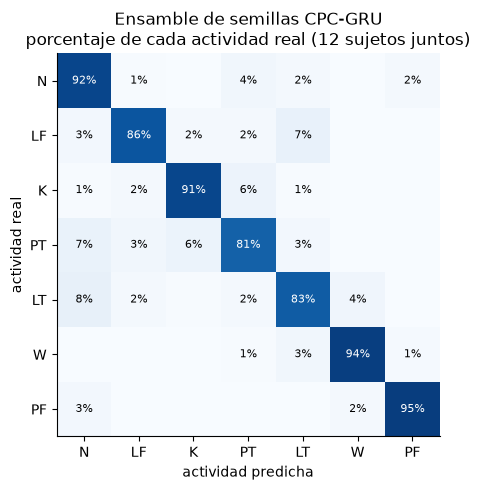

In [21]:
# Matriz normalizada por fila: cada fila suma 100 % de las ventanas de esa actividad real
y, pred = pooled(FINAL)
cm = confusion_matrix(y, pred, labels=range(len(LABELS)), normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        if cm[i, j] >= 0.005:
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.6 else "black")
ax.set(xticks=range(len(LABELS)), xticklabels=LABELS, yticks=range(len(LABELS)), yticklabels=LABELS,
       xlabel="actividad predicha", ylabel="actividad real",
       title=f"{FINAL}\nporcentaje de cada actividad real ({len(FOLDS)} sujetos juntos)")
plt.tight_layout()
plt.show()

De acuerdo a la matriz de confusión de nuestro mejor modelo, la diagonal va de 81 % (`PT`) a 95 % (`PF` y `W`). Los errores se concentran en pocos pares de actividades vecinas en el tiempo o parecidas en el movimiento:

- **`LT` → `N` (8 %) y `PT` → `N` (7 %).** Levantar o colocar en la mesa se confunde con la postura neutral, de la que parten y a la que regresan. Es el error más frecuente.
- **`PT` ↔ `K` (6 % en cada sentido).** Colocar en la mesa y mantener la carga levantada comparten los brazos frente al cuerpo con la carga a media altura.
- **`LF` → `LT` (7 %).** Las dos son levantamientos; las distingue la altura desde la que se toma la carga.
- **`LT` ↔ `W` (4 %).** Después de levantar desde la mesa se suele caminar con la carga.

Casi no hay confusiones entre caminar y estar quieto (`W` ↔ `N`, 0 %) ni entre actividades del piso y de la mesa en sentido opuesto (`PF` ↔ `LT`, ≤ 0.1 %). Para un análisis ergonómico, confundir levantar desde el piso con una actividad a la altura de la mesa sería el error más costoso. Los errores encontrados son sobre todo de **frontera entre actividades consecutivas**.

## 11.3 Importancia de las variables

La representación `c_T` son 256 números (768 en los ensambles) sin significado físico propio. Por eso la importancia se mide sobre las **30 variables de entrada**, **por permutación**: en las ventanas del sujeto evaluado se intercambia al azar, entre ventanas, la trayectoria completa de una variable; se recalcula todo el modelo (CPC + sonda o ensamble) y se mide cuánto baja el F1 macro. Una caída grande quiere decir que el modelo depende de esa variable. Se promedia en las 12 rondas.

2026-10-31 23:35 | importancia · sujeto  1 listo


2026-10-31 23:36 | importancia · sujeto  2 listo


2026-10-31 23:37 | importancia · sujeto  3 listo


2026-10-31 23:38 | importancia · sujeto  4 listo


2026-10-31 23:39 | importancia · sujeto  5 listo


2026-10-31 23:40 | importancia · sujeto  6 listo


... (2 outputs left out)

2026-10-31 23:44 | importancia · sujeto  9 listo


2026-10-31 23:44 | importancia · sujeto 10 listo


2026-10-31 23:46 | importancia · sujeto 11 listo


2026-10-31 23:47 | importancia · sujeto 12 listo


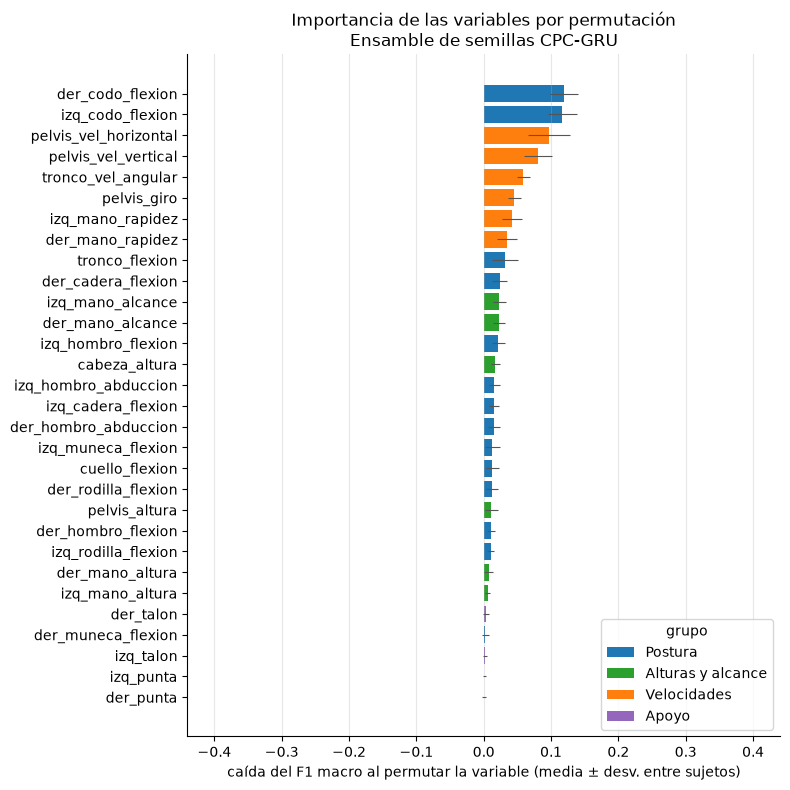

,caída total del grupo,variable más importante
grupo,,
Postura,0.421,0.119
Velocidades,0.358,0.097
Alturas y alcance,0.088,0.023
Apoyo,0.007,0.004


In [22]:
def final_predictor(held_out):
    """Reconstruye el modelo final de una ronda con los hiperparámetros ya elegidos (sin volver a buscarlos)."""
    rnd = prepare_round(held_out)
    names = MODELS[FINAL]["cpc"]
    feats = {}
    for c in names:
        feats.update(round_features(c, rnd, parts=("probe_train", "val")))
    model, _, _ = fit_model(FINAL, feats, rnd["sets"], params=EVAL[held_out]["modelos"][FINAL]["params"])
    return rnd, {c: load_cpc(c, held_out) for c in names}, model


def predict_windows(cpcs, model, X):
    """Probabilidades del modelo final para ventanas ya armadas (tensor), pasando por sus CPC."""
    feats = {}
    for c, net in cpcs.items():
        for branch, arr in representations(net, X).items():
            feats[c if branch == "" else f"{c}:{branch}"] = {"held": arr}
    return model.predict_proba(feats, "held")


path = RUN_DIR / f"importancia_{re.sub(r'[^A-Za-z0-9]+', '_', FINAL)}.json"
if path.exists():                                                             # ya calculada: se carga
    drops = json.loads(path.read_text())
else:
    drops = {}                                                                # {variable: [caída de F1 en cada ronda]}
    for held_out in FOLDS:
        rnd, cpcs, model = final_predictor(held_out)
        held = rnd["sets"]["held"]
        X = get_windows(held["starts"])                                       # ventanas del sujeto evaluado
        base = f1_score(held["y"], predict_windows(cpcs, model, X).argmax(1), average="macro")   # F1 sin permutar
        rng = np.random.default_rng(held_out)
        for j, var in enumerate(CHANNELS):
            Xp = X.clone()
            Xp[:, j, :] = X[torch.as_tensor(rng.permutation(len(X)), device=DEVICE), j, :]   # trayectoria de otra ventana
            drops.setdefault(var, []).append(base - f1_score(held["y"], predict_windows(cpcs, model, Xp).argmax(1), average="macro"))
        log(f"importancia · sujeto {held_out:2d} listo")
        del cpcs, X
    path.write_text(json.dumps(drops))

# Gráfica: caída media de F1 por variable, coloreada por grupo
importance = pd.DataFrame({"caída de F1": {v: np.mean(d) for v, d in drops.items()},
                           "desv.": {v: np.std(d) for v, d in drops.items()},
                           "grupo": {v: feature_group(v) for v in drops}}).sort_values("caída de F1")
GROUP_COLORS = {"Postura": "#1f77b4", "Alturas y alcance": "#2ca02c", "Velocidades": "#ff7f0e", "Apoyo": "#9467bd"}
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(importance.index, importance["caída de F1"], xerr=importance["desv."], color=importance["grupo"].map(GROUP_COLORS),
        error_kw={"elinewidth": 0.8, "ecolor": "#555"})
for g, c in GROUP_COLORS.items():
    ax.bar(0, 0, color=c, label=g)
ax.legend(loc="lower right", title="grupo")
ax.set(xlabel="caída del F1 macro al permutar la variable (media ± desv. entre sujetos)",
       title=f"Importancia de las variables por permutación\n{FINAL}")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
display(importance.groupby("grupo")["caída de F1"].agg(["sum", "max"]).sort_values("sum", ascending=False)
        .rename(columns={"sum": "caída total del grupo", "max": "variable más importante"}).style.format("{:.3f}"))

- **Las variables más importantes** son la **flexión de ambos codos** (caída del F1 de 0.119 y 0.117), las **velocidades horizontal y vertical de la pelvis** (0.097 y 0.080) y la **velocidad angular del tronco** (0.059).
  - El codo cambia entre sostener la carga pegada al cuerpo y extender los brazos para tomarla o dejarla.
  - La pelvis refleja el desplazamiento al caminar y el descenso o ascenso del cuerpo en las actividades del piso.
- **Por grupo:** la postura (0.421) y las velocidades (0.358) concentran casi toda la importancia. Las alturas y el alcance de las manos aportan poco (0.088). Los contactos de los pies casi nada: menos de 0.004 cada uno.
- **Precaución al leer la figura:** se permuta una variable a la vez. Cuando dos variables llevan información parecida, permutar una sola casi no afecta, porque la otra la sustituye. Así, una importancia baja no significa que la variable no tenga información. Por ejemplo, la altura de las manos depende de la flexión de codo, hombro y tronco. Además, la *caída total del grupo* es la suma de las caídas individuales, no la caída al permutar todo el grupo a la vez.
- **Lectura para el negocio:** los contactos de los pies son candidatos a eliminarse en una versión simplificada del sistema. Habría que confirmarlo reentrenando sin ellos.

## 11.4 Desempeño con pocas etiquetas

En una planta real se pueden grabar muchas horas de movimiento, pero **etiquetar** cada actividad es caro. El preentrenamiento CPC no usa etiquetas, así que su ventaja debería aparecer cuando hay pocas. Para medirlo, en cada ronda se entrena el clasificador con sólo **1, 5, 10, 25, 50 o 100 ventanas etiquetadas por actividad**, tomadas al azar de los sujetos de entrenamiento (3 repeticiones por tamaño), y se evalúa en el sujeto evaluado.

- **Modelos CPC:** los CPC no cambian, porque se preentrenaron sin etiquetas. Sólo la sonda (o las sondas del ensamble) ve las ventanas etiquetadas, con los hiperparámetros elegidos en la sección 9.
- **Random Forest:** se entrena con las mismas ventanas etiquetadas.

2026-10-31 23:47 | pocas etiquetas · sujeto  1 listo


2026-10-31 23:48 | pocas etiquetas · sujeto  2 listo


2026-10-31 23:48 | pocas etiquetas · sujeto  3 listo


2026-10-31 23:48 | pocas etiquetas · sujeto  4 listo


2026-10-31 23:49 | pocas etiquetas · sujeto  5 listo


2026-10-31 23:49 | pocas etiquetas · sujeto  6 listo


... (2 outputs left out)

2026-10-31 23:50 | pocas etiquetas · sujeto  9 listo


2026-10-31 23:51 | pocas etiquetas · sujeto 10 listo


2026-10-31 23:51 | pocas etiquetas · sujeto 11 listo


2026-10-31 23:52 | pocas etiquetas · sujeto 12 listo


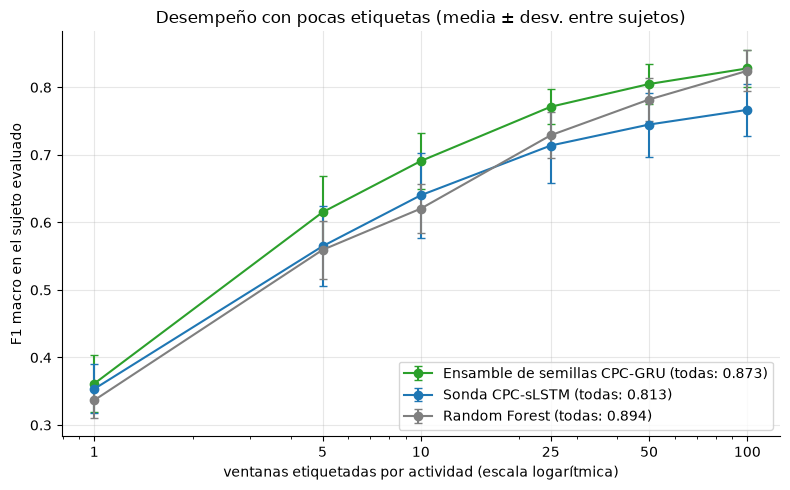

,Ensamble de semillas CPC-GRU,Sonda CPC-sLSTM,Random Forest
1 por actividad (7 en total),0.361,0.353,0.337
5 por actividad (35 en total),0.615,0.565,0.559
10 por actividad (70 en total),0.691,0.640,0.620
25 por actividad (175 en total),0.771,0.714,0.729
50 por actividad (350 en total),0.805,0.745,0.782
100 por actividad (700 en total),0.828,0.767,0.824


In [23]:
# Modelos de la curva: el final y la mejor sonda individual (el Random Forest se agrega como referencia)
CURVE_MODELS = [FINAL] if FINAL != BEST_BASE else []
CURVE_MODELS += [BEST_BASE]
if any(n.startswith(("Stacking", "Blending")) for n in CURVE_MODELS):
    print("El stacking y el blending necesitan más datos que ventanas por actividad para su meta-modelo; se omiten en la curva.")
    CURVE_MODELS = [n for n in CURVE_MODELS if not n.startswith(("Stacking", "Blending"))]


def subsample(y, n, rng):
    """`n` ventanas de cada actividad (o todas las que haya), al azar."""
    return np.concatenate([rng.choice(np.flatnonzero(y == c), min(n, (y == c).sum()), replace=False) for c in range(len(LABELS))])


def restrict(feats, idx):
    """Representaciones con sólo las ventanas `idx` del conjunto de entrenamiento."""
    return {s: {**parts, "probe_train": parts["probe_train"][idx]} for s, parts in feats.items()}


path = RUN_DIR / "pocas_etiquetas.json"
curve = json.loads(path.read_text()) if path.exists() else []                # filas ya calculadas (se puede reanudar)
done = {(c["sujeto"], c["n"], c["rep"]) for c in curve}
for held_out in FOLDS:
    if all((held_out, n, rep) in done for n in LABEL_SIZES for rep in range(LABEL_REPS)):
        continue
    rnd = prepare_round(held_out)
    sets = rnd["sets"]
    # Representaciones de los CPC: se calculan una vez por ronda; sólo cambia cuántas ventanas etiquetadas ve el clasificador
    feats = {}
    for c in sorted({c for m in CURVE_MODELS for c in MODELS[m]["cpc"]}):
        feats.update(round_features(c, rnd))
    tr_tab = X_tab.loc[sets["probe_train"]["index"]].to_numpy()             # las mismas ventanas, en formato del Random Forest
    held_tab = X_tab.loc[sets["held"]["index"]].to_numpy()
    for n in LABEL_SIZES:
        for rep in range(LABEL_REPS):
            # n ventanas etiquetadas por actividad; la repetición cambia cuáles
            idx = subsample(sets["probe_train"]["y"], n, np.random.default_rng(rep))
            sub = {**sets, "probe_train": {k: v[idx] for k, v in sets["probe_train"].items()}}
            row = {"sujeto": held_out, "n": n, "rep": rep}
            for m in CURVE_MODELS:
                model, _, _ = fit_model(m, restrict(feats, idx), sub, params=EVAL[held_out]["modelos"][m]["params"])
                row[m] = f1_score(sets["held"]["y"], model.predict_proba(feats, "held").argmax(1), average="macro")
            rf = RandomForestClassifier(**{**RF_PARAMS, "random_state": rep}).fit(tr_tab[idx], sets["probe_train"]["y"][idx])
            row["Random Forest"] = f1_score(sets["held"]["y"], rf.predict(held_tab), average="macro")
            curve.append(row)
    path.write_text(json.dumps(curve))
    log(f"pocas etiquetas · sujeto {held_out:2d} listo")

# Gráfica y tabla: F1 medio entre sujetos para cada número de etiquetas
curve_df = pd.DataFrame(curve)
curve_df = curve_df[curve_df["sujeto"].isin(FOLDS)]
by_n = curve_df.groupby(["n", "sujeto"]).mean().drop(columns="rep").groupby("n")   # promedio de repeticiones, luego de sujetos
mean, sd = by_n.mean(), by_n.std()
full = {m: summary.loc[m, "F1 macro"] for m in CURVE_MODELS + ["Random Forest"]}

fig, ax = plt.subplots(figsize=(8, 5))
colors = {FINAL: "#2ca02c", BEST_BASE: "#1f77b4", "Random Forest": "#7f7f7f"}
for m in CURVE_MODELS + ["Random Forest"]:
    ax.errorbar(mean.index, mean[m], yerr=sd[m], marker="o", capsize=3, color=colors.get(m), label=f"{m} (todas: {full[m]:.3f})")
ax.set_xscale("log")
ax.set_xticks(LABEL_SIZES, [str(n) for n in LABEL_SIZES])
ax.set(xlabel="ventanas etiquetadas por actividad (escala logarítmica)", ylabel="F1 macro en el sujeto evaluado",
       title="Desempeño con pocas etiquetas (media ± desv. entre sujetos)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
table = mean.copy()
table.index = [f"{n} por actividad ({n * len(LABELS)} en total)" for n in table.index]
display(table.style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold"))

**Interpretación.** El ensamble de semillas supera al Random Forest **con todas las cantidades de etiquetas probadas**. La ventaja es mayor cuando hay pocas:

| Ventanas etiquetadas por actividad | Ventaja del ensamble sobre el Random Forest (F1 macro) |
|---|---|
| 5 | +0.056 |
| 10 | +0.071 |
| 25 | +0.042 |
| 100 | +0.004 |

Con todas las etiquetas (sección 10), el Random Forest queda arriba: 0.894 contra 0.873.

- **Las curvas se cruzan** entre 100 ventanas por actividad y el conjunto completo de etiquetas.
- **Con 50 ventanas por actividad** (350 en total), el ensamble alcanza 0.805, el 92 % del F1 que logra con todas las etiquetas.
- **La mejor sonda individual (sLSTM)** también supera al Random Forest con 1 a 10 ventanas por actividad, pero queda debajo desde 25.
- **Con una sola ventana por actividad**, ningún modelo es útil (F1 ≈ 0.34–0.36).

Justo en este punto se enfatiza la ventaja del uso de un modelo no supervisado, como el CPC, sobre el uso común de un modelo supervisado. En una planta nueva se pueden grabar muchas horas de movimiento sin etiquetar. El CPC aprovecha esas grabaciones y sólo el clasificador lineal necesita etiquetas. Con unas decenas de ejemplos por actividad, el ensamble CPC entrega mejores resultados que el modelo clásico con las mismas etiquetas.

### **Almacenamiento de los modelos**

Los modelos ejecutados en este notebook se almacenaron en la siguiente liga de Drive: 
*  https://drive.google.com/drive/folders/1WuSs0j5d5-l-nCP_BxqECXCYBhA2W0Gq?usp=drive_link

# 12. Conclusiones

1. **El ensamble homogéneo es la estrategia que más aporta.**
   - Promediar cinco CPC-GRU sube el F1 macro de una sola sonda CPC-GRU de 0.811 a 0.873.
   - El peor sujeto pasa de 0.662 a 0.827: en el sujeto 1, la sonda individual daba 0.662 y el ensamble 0.864.
   - Una sola sonda dependía mucho de la semilla con la que se preentrenó el CPC; el promedio reduce esa variación.
2. **Los ensambles heterogéneos mejoran a cada sonda, pero menos que las semillas.**
   - Logran 0.837–0.846, contra 0.788–0.813 de las sondas individuales.
   - Incluyen la sonda LSTM, la más débil (0.788). No se midió qué tan parecidos son los errores de los tres modelos.
   - El stacking (0.840) no superó a la votación suave (0.846). Su meta-modelo eligió en 11 de 12 rondas la regularización más fuerte probada (`C` = 0.01).
   - El blending fue el peor ensamble (0.813) pese a tener el mayor F1 en validación (0.880). Su meta-modelo se ajusta con un solo sujeto, se sobreajusta a él y no generaliza.
3. **El CPC con tres autorregresivos (0.831)** supera a cualquier sonda individual. Queda debajo de concatenar los tres CPC entrenados por separado (0.837) y del ensamble de semillas, y cuesta 8.4 min por ronda. Compartir el encoder no aportó.
4. **Optimización de hiperparámetros.**
   - En el ensamble de semillas, la validación eligió el máximo de semillas probado (5) en 8 de 12 rondas, y el promedio de probabilidades en 9 de 12. Más semillas podrían ayudar todavía.
   - Todos los valores se eligieron sin ver al sujeto evaluado.
5. **Modelo final: ensamble de semillas CPC-GRU.** Se compara con los criterios del negocio:
   - **Desempeño:** F1 macro 0.873. Queda a 0.021 del Random Forest y a 0.005 de la GRU con ajuste fino, usando sólo un clasificador lineal sobre la representación aprendida sin etiquetas.
   - **Estabilidad entre personas:** el peor sujeto (0.827) y la desviación (0.021) son comparables o mejores que los del Random Forest (0.823 y 0.026).
   - **Pocas etiquetas:** supera al Random Forest con todos los tamaños probados.
   - **Costo:** el entrenamiento es el más caro (9.8 min por ronda, por los cinco preentrenamientos), pero se hace una sola vez y sin etiquetas. El modelo es causal, condición para usarlo en tiempo real. La latencia no se midió.
6. **Limitaciones y siguientes pasos.**
   - Evaluar el modelo final en los sujetos reservados 13 y 14.
   - Probar más de cinco semillas.
   - Medir la latencia del ensamble.
   - Varios ajustes de la regresión logística llegaron al límite de 2000 iteraciones sin terminar de converger durante la evaluación. Conviene aumentar el límite o revisar el escalado en la siguiente fase.

# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). Claude Code (Claude Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.com/claude-code | Generar y optimizar el código de preparación de datos y del modelo base: configuración, lectura y recuperación de ensayos MVNX, cálculo de las 30 variables, ventanas, protocolo de validación LOSO y clases del modelo CPC | Celdas 4, 6–8, 10, 12, 14–16 y 20 (secciones 1–4 y 4.2) | **Dylan Ulises Quiroz Hernández.** Verificó que la lectura del MVNX crudo reproduce la exportación sincronizada (control automático de la celda 7) y que las ventanas evaluadas coinciden con las del notebook 10 (celda 12) |
| Anthropic. (2026). Claude Code (Claude Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.com/claude-code | Generar y optimizar el código de los ensambles y de la optimización de hiperparámetros: semillas de CPC-GRU, concatenación, votación suave, stacking, blending y CPC con tres autorregresivos | Celdas 18, 25, 27, 29, 31 y 33 (secciones 4.1 y 6–9) | **Isaura Yutsil Flores Escamilla.** Definió las estrategias y los rangos de hiperparámetros, ejecutó una prueba corta con 2 rondas y la corrida LOSO completa, y verificó que la sonda CPC-GRU reproduce las predicciones del notebook 10 (100 % de acuerdo en las 12 rondas) |
| Anthropic. (2026). Claude Code (Claude Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.com/claude-code | Generar y optimizar el código de la comparación y del análisis del modelo final: modelos individuales del avance 4, tabla comparativa, F1 por actividad, matriz de confusión, importancia por permutación y curva con pocas etiquetas | Celdas 22, 35, 37, 39, 42, 45 y 48 (secciones 5, 10 y 11) | **Paola Alejandra León Guarneros.** Verificó que los modelos individuales reproducen los resultados del avance 4 (Random Forest 0.894, GRU con CPC 0.878) y revisó las figuras y su interpretación |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Isaura Yutsil Flores Escamilla | Definió el enfoque del avance: ensambles dentro del CPC, con el Random Forest sólo como referencia. Implementó y ejecutó los ensambles (semillas, ensambles heterogéneos y CPC con tres autorregresivos) y la optimización de hiperparámetros con validación LOSO, y comparó el proyecto con Bassani et al. (2025). |
| Paola Alejandra León Guarneros | Integró los modelos individuales del avance 4, con el Random Forest como referencia. Construyó la tabla comparativa y el análisis del modelo final: F1 por actividad, matriz de confusión, importancia de las variables y curva con pocas etiquetas. |
| Dylan Ulises Quiroz Hernández | Preparó los datos de entrada: lectura y recuperación de ensayos MVNX, cálculo de las 30 variables y ventanas. Implementó el protocolo de validación LOSO y adaptó el modelo CPC base. |

### Decisiones principales

<small><b>Decisión 1:</b> Construir los ensambles sobre el preentrenamiento CPC con clasificador lineal, y dejar el Random Forest como referencia</small>

- <small>Justificación: El objetivo del proyecto es mostrar que la representación aprendida sin etiquetas basta para que un clasificador lineal distinga las actividades. Los ensambles combinan representaciones o sondas CPC (semillas, distintos autorregresivos y un CPC con tres autorregresivos), así que cualquier mejora se debe a la representación y no a un clasificador más complejo.</small>
- <small>Alternativa descartada y motivo: Ensamblar el Random Forest con las redes (por ejemplo, stacking de árboles y redes), porque mezclaría el aporte de las características manuales con el de la representación autosupervisada y no permitiría medir el valor del CPC.</small>

<small><b>Decisión 2:</b> Optimizar los hiperparámetros dentro de cada ronda con un sujeto de validación interna</small>

- <small>Justificación: La regularización de las sondas, el número de semillas, la forma de combinarlas y la regularización del meta-modelo se eligen sin ver al sujeto evaluado. Así, el F1 de la tabla comparativa estima el desempeño en una persona nueva.</small>
- <small>Alternativa descartada y motivo: Elegir los hiperparámetros con el promedio LOSO, porque usaría al sujeto evaluado para decidir y daría resultados optimistas. El blending muestra el riesgo: tuvo el mejor F1 en validación (0.880) y uno de los peores en el sujeto evaluado (0.813).</small>

<small><b>Decisión 3:</b> Elegir el modelo final con los criterios del negocio, incluido el desempeño con pocas etiquetas</small>

- <small>Justificación: Etiquetar actividades es la parte más cara de llevar el sistema a una planta. El ensamble de semillas CPC-GRU supera al Random Forest con 1 a 100 ventanas etiquetadas por actividad. Con todas las etiquetas queda a 0.021 de F1 y con un peor sujeto comparable.</small>
- <small>Alternativa descartada y motivo: Elegir el Random Forest por tener el mayor F1 con todas las etiquetas, porque no aprovecha las grabaciones sin etiquetar y pierde ventaja justo en el escenario más probable de una planta nueva: pocas etiquetas.</small>